# Data Preprocessing Workflow

Preprocess `dataset/data.csv` including: handling missing values, encoding non-numeric data, preliminary statistical analysis, and visualization.

Ablation outputs:
- Original preprocessing workflow with the Section 4 encoding method: `data/processed_org/{train,val,test}.csv`
- Split-first preprocessing workflow with train-only imputation statistics and `pd.get_dummies`: `data/processed/{train,val,test}.csv`

## 1. Import packages

In [116]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100
print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Load CSV raw data


Due to the large size, use `nrows`, read 5 lines to preview the structure, and then load the entire dataset to preprocess. 

In [117]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "preprocess" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "dataset" / "data.csv"
OUTPUT_PATH = PROJECT_ROOT / "dataset" / "processed_data.csv"
ORG_OUTPUT_DIR = PROJECT_ROOT / "data" / "processed_org"
ALT_OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"

# Use nrows for preview
preview = pd.read_csv(DATA_PATH, sep=';', nrows=5)
print(f"Raw data path: {DATA_PATH}")
print(f"Rows: {preview.shape[0]},  Columns: {preview.shape[1]}")
print("\nColumn names:")
print(list(preview.columns))
preview

Raw data path: e:\Python\Machine-Learning-Project\dataset\data.csv
Rows: 5,  Columns: 37

Column names:
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance\t', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular u

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0000,1,19,12,5,9,127.3000,1,0,0,1,1,0,20,0,0,0,0,0,0.0000,0,0,0,0,0,0.0000,0,10.8000,1.4000,1.7400,Dropout
1,1,15,1,9254,1,1,160.0000,1,1,3,3,3,142.5000,1,0,0,0,1,0,19,0,0,6,6,6,14.0000,0,0,6,6,6,13.6667,0,13.9000,-0.3000,0.7900,Graduate
2,1,1,5,9070,1,1,122.0000,1,37,37,9,9,124.8000,1,0,0,0,1,0,19,0,0,6,0,0,0.0000,0,0,6,0,0,0.0000,0,10.8000,1.4000,1.7400,Dropout
3,1,17,2,9773,1,1,122.0000,1,38,37,5,3,119.6000,1,0,0,1,0,0,20,0,0,6,8,6,13.4286,0,0,6,10,5,12.4000,0,9.4000,-0.8000,-3.1200,Graduate
4,2,39,1,8014,0,1,100.0000,1,37,38,9,9,141.5000,0,0,0,1,0,0,45,0,0,6,9,5,12.3333,0,0,6,6,6,13.0000,0,13.9000,-0.3000,0.7900,Graduate


In [118]:
# Load the full dataset
df = pd.read_csv(DATA_PATH, sep=';')
print(f"Dataset shape: {df.shape}")
print(f"\nData types:\n{df.dtypes}")

Dataset shape: (4424, 37)

Data types:
Marital status                                      int64
Application mode                                    int64
Application order                                   int64
Course                                              int64
Daytime/evening attendance\t                        int64
Previous qualification                              int64
Previous qualification (grade)                    float64
Nacionality                                         int64
Mother's qualification                              int64
Father's qualification                              int64
Mother's occupation                                 int64
Father's occupation                                 int64
Admission grade                                   float64
Displaced                                           int64
Educational special needs                           int64
Debtor                                              int64
Tuition fees up to date          

## 3. Handling Missing Values

In [119]:
# Count missing values and their proportions for each column
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"Missing Count": missing, "Missing Percentage (%)": missing_pct})
missing_df = missing_df[missing_df["Missing Count"] > 0].sort_values("Missing Percentage (%)", ascending=False)

if missing_df.empty:
    print("No missing values in the dataset.")
else:
    print(f"Columns with missing values (total {len(missing_df)} columns):")
    print(missing_df)

No missing values in the dataset.


In [120]:
DROP_THRESHOLD = 50.0  # Drop columns if missing rate exceeds this threshold

# Remove columns with high missing rates
cols_to_drop = missing_df[missing_df["Missing Percentage (%)"] > DROP_THRESHOLD].index.tolist()
if cols_to_drop:
    df.drop(columns=cols_to_drop, inplace=True)
    print(f"Dropped columns with missing rate > {DROP_THRESHOLD}%: {cols_to_drop}")

# Fill numeric columns with median, categorical columns with mode
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

for col in num_cols:
    if df[col].isnull().any():
        median_val = df[col].median()
        df[col].fillna(median_val, inplace=True)
        print(f"  Numeric column '{col}': filled missing values with median {median_val:.4f}")

for col in cat_cols:
    if df[col].isnull().any():
        mode_val = df[col].mode()[0]
        df[col].fillna(mode_val, inplace=True)
        print(f"  Categorical column '{col}': filled missing values with mode '{mode_val}'")

print(f"\nTotal missing values after processing: {df.isnull().sum().sum()}")


Total missing values after processing: 0


## 4. Handling Non-Numeric Data

Identify all string/categorical columns, apply `LabelEncoder` for encoding, and record the mappings.

In [121]:
# Re-detect non-numeric columns (may change after handling missing values)
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
print(f"Non-numeric columns: {cat_cols}")

label_encoders = {}
label_mappings = {}

for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le
    label_mappings[col] = dict(zip(le.classes_, le.transform(le.classes_)))
    print(f"\nColumn '{col}' encoding mapping: {label_mappings[col]}")

print("\nEncoding completed. All columns are now numeric.")
print(f"Dataset shape: {df.shape}")

Non-numeric columns: ['Target']

Column 'Target' encoding mapping: {'Dropout': np.int64(0), 'Enrolled': np.int64(1), 'Graduate': np.int64(2)}

Encoding completed. All columns are now numeric.
Dataset shape: (4424, 37)


## 5. Preliminary Statistical Analysis

In [122]:
# Descriptive statistics (mean, variance, std, quantiles, etc.)
stats = df.describe().T
stats["variance"] = df.var()
stats["skewness"] = df.skew()
stats["kurtosis"] = df.kurtosis()
stats = stats[["count", "mean", "variance", "std", "min", "25%", "50%", "75%", "max", "skewness", "kurtosis"]]
stats.columns = ["Count", "Mean", "Variance", "Std Dev", "Min", "Q1", "Median", "Q3", "Max", "Skewness", "Kurtosis"]
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)
stats

,Count,Mean,Variance,Std Dev,Min,Q1,Median,Q3,Max,Skewness,Kurtosis
Marital status,4424.0000,1.1786,0.3669,0.6057,1.0000,1.0000,1.0000,1.0000,6.0000,4.3998,21.4826
Application mode,4424.0000,18.6691,305.7141,17.4847,1.0000,1.0000,17.0000,39.0000,57.0000,0.3930,-1.4538
Application order,4424.0000,1.7278,1.7261,1.3138,0.0000,1.0000,1.0000,2.0000,9.0000,1.8810,2.6513
Course,4424.0000,8856.6426,4258306.3541,2063.5664,33.0000,9085.0000,9238.0000,9556.0000,9991.0000,-3.8091,13.1991
Daytime/evening attendance\t,4424.0000,0.8908,0.0973,0.3119,0.0000,1.0000,1.0000,1.0000,1.0000,-2.5072,4.2882
Previous qualification,4424.0000,4.5778,104.3788,10.2166,1.0000,1.0000,1.0000,1.0000,43.0000,2.8712,6.7782
Previous qualification (grade),4424.0000,132.6133,173.9321,13.1883,95.0000,125.0000,133.1000,140.0000,190.0000,0.3129,0.9683
Nacionality,4424.0000,1.8732,47.8105,6.9145,1.0000,1.0000,1.0000,1.0000,109.0000,10.7040,135.1462
Mother's qualification,4424.0000,19.5619,243.4594,15.6032,1.0000,2.0000,19.0000,37.0000,44.0000,0.0020,-1.6923
Father's qualification,4424.0000,22.2753,235.4110,15.3431,1.0000,3.0000,19.0000,37.0000,44.0000,-0.2987,-1.5806


In [123]:
# Correlation matrix (sorted by absolute value, display top 10 features with highest correlation to Target)
corr_matrix = df.corr()
if "Target" in corr_matrix.columns:
    target_corr = corr_matrix["Target"].drop("Target").abs().sort_values(ascending=False)
    print("Top 10 features with highest correlation to Target:")
    print(target_corr.head(10))

Top 10 features with highest correlation to Target:
Curricular units 2nd sem (approved)   0.6242
Curricular units 2nd sem (grade)      0.5668
Curricular units 1st sem (approved)   0.5291
Curricular units 1st sem (grade)      0.4852
Tuition fees up to date               0.4098
Scholarship holder                    0.2976
Age at enrollment                     0.2434
Debtor                                0.2410
Gender                                0.2293
Application mode                      0.2217
Name: Target, dtype: float64


## 6. Data Distribution Visualization

Continuous features for plotting (21 columns): ['Application mode', 'Course', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)']


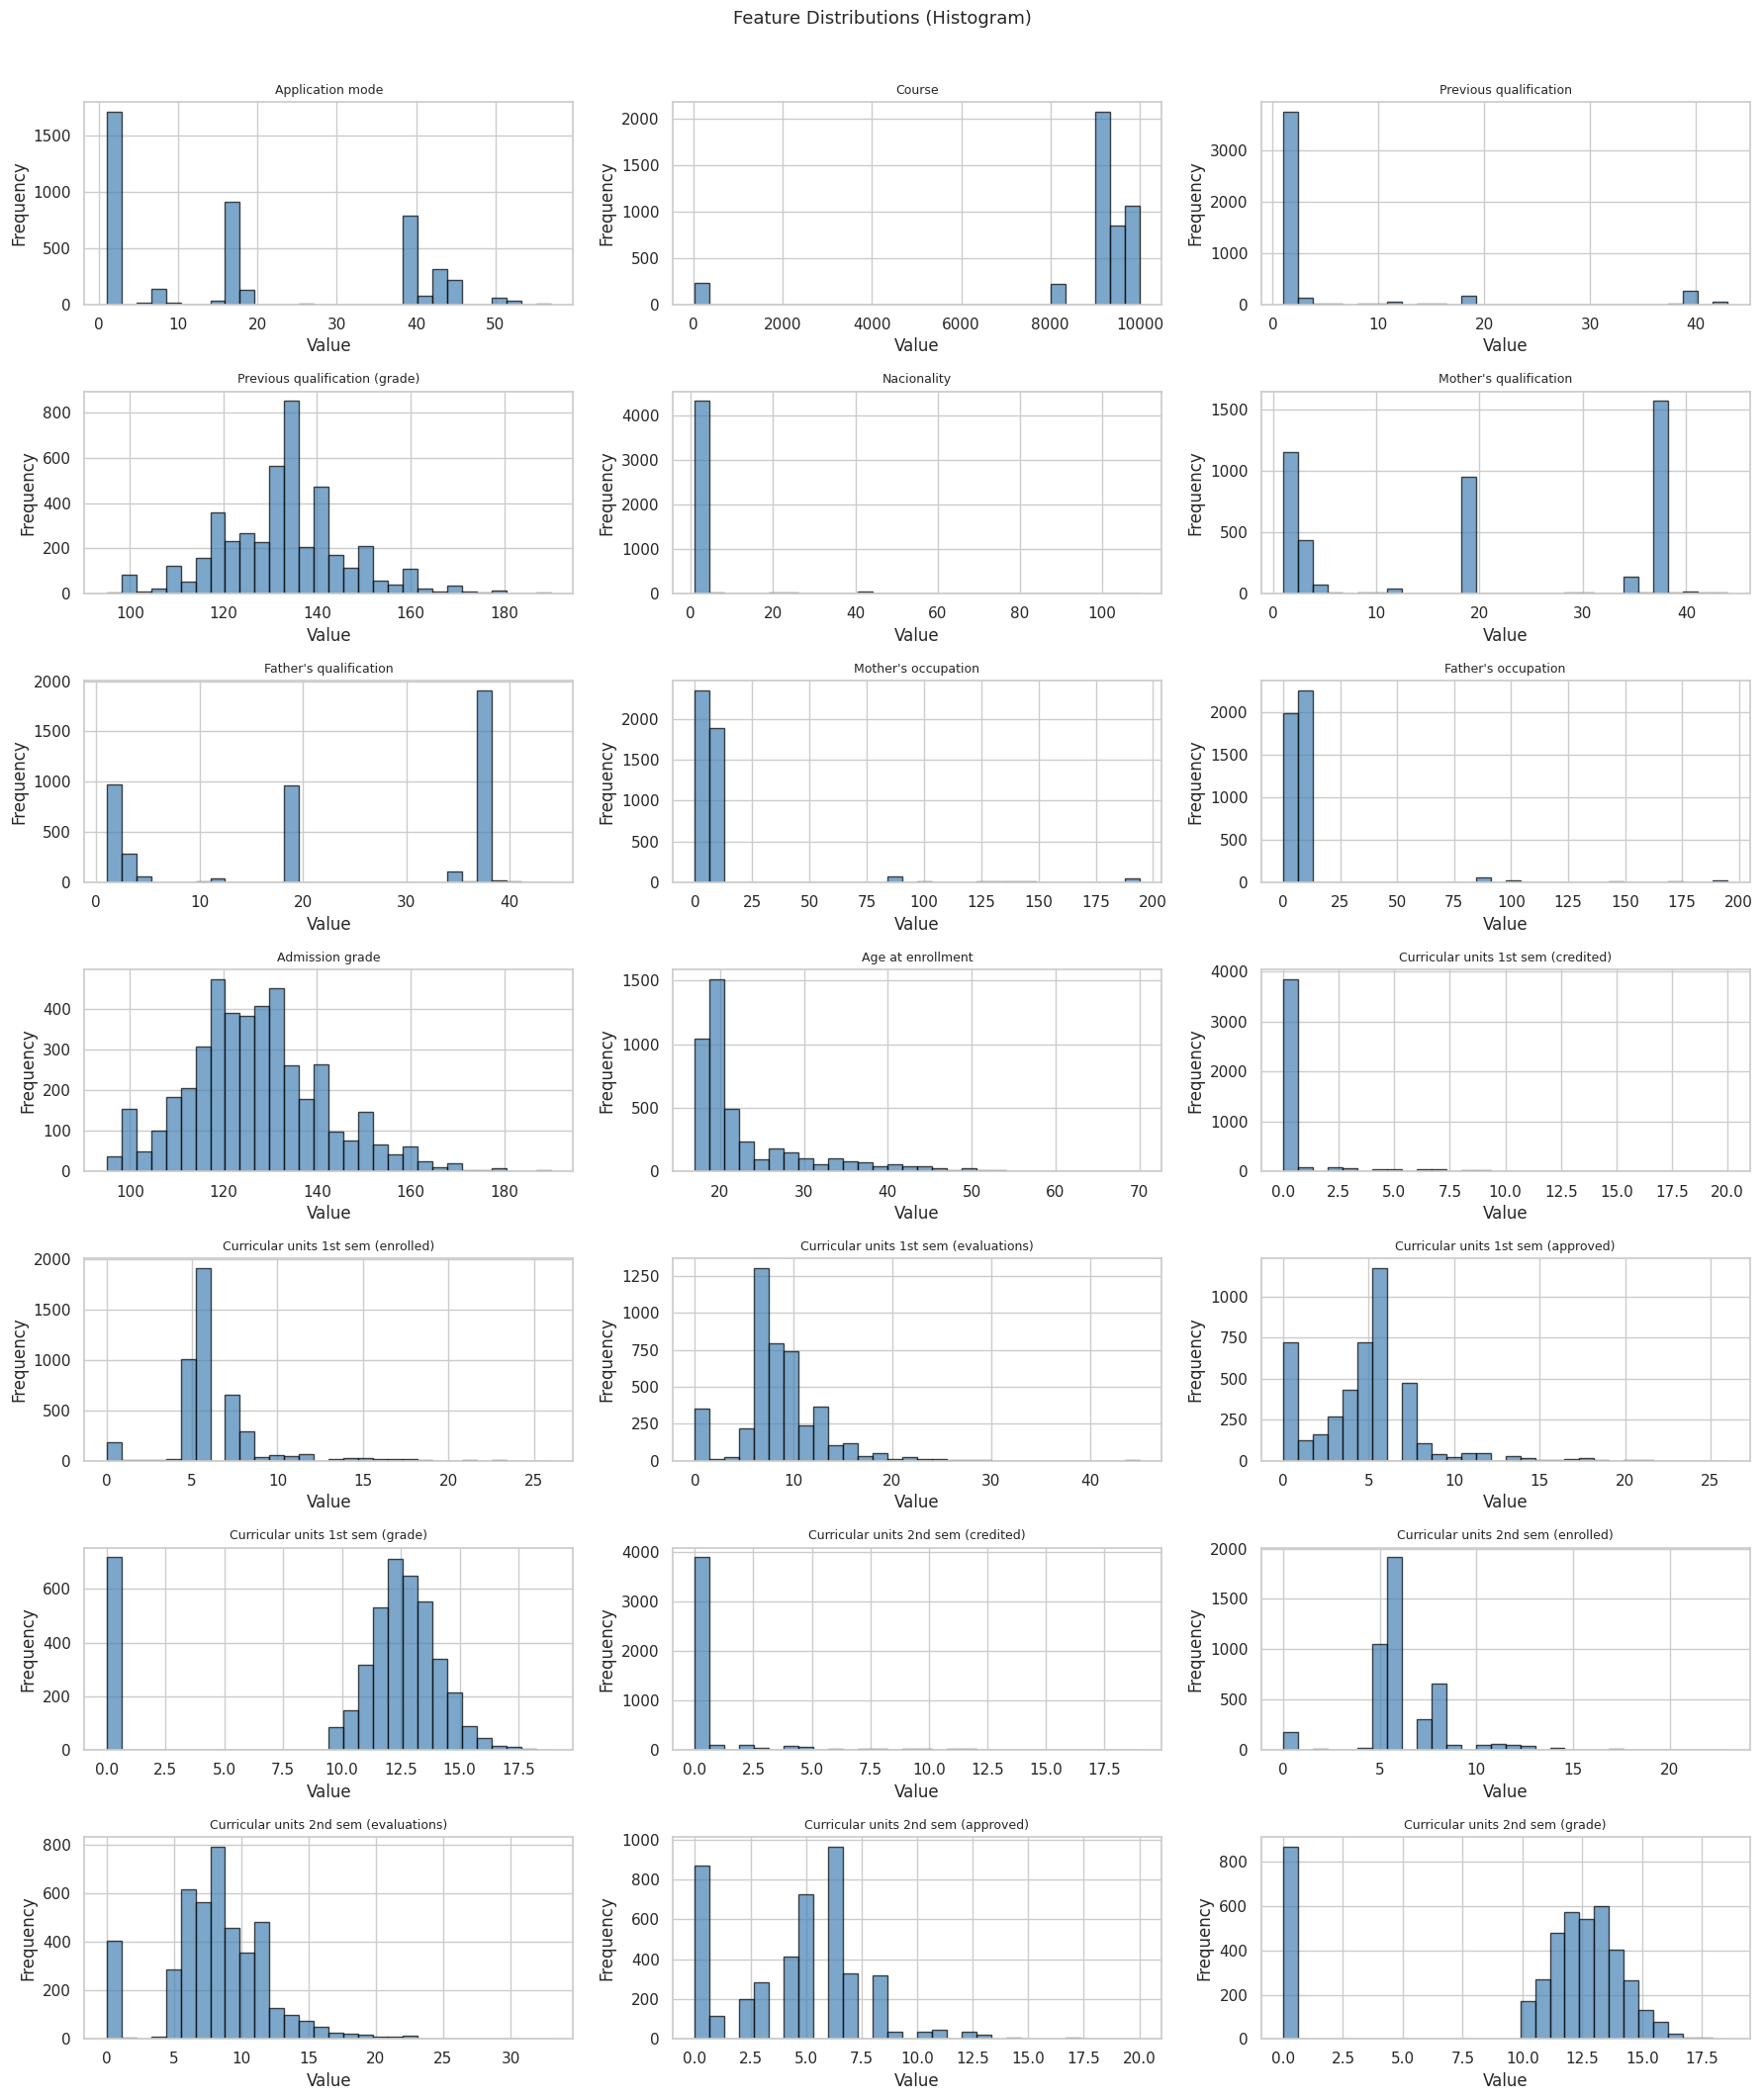

In [124]:
# Select continuous numeric features (treat low-cardinality columns as categorical, skip them)
CARDINALITY_THRESHOLD = 15
continuous_cols = [c for c in df.columns if df[c].nunique() > CARDINALITY_THRESHOLD]
print(f"Continuous features for plotting ({len(continuous_cols)} columns): {continuous_cols}")

# Histogram
n = len(continuous_cols)
if n > 0:
    ncols = 3
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 3))
    axes = axes.flatten()
    for i, col in enumerate(continuous_cols):
        axes[i].hist(df[col].dropna(), bins=30, edgecolor='black', color='steelblue', alpha=0.7)
        axes[i].set_title(f"{col}", fontsize=9)
        axes[i].set_xlabel("Value")
        axes[i].set_ylabel("Frequency")
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)
    plt.suptitle("Feature Distributions (Histogram)", fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()

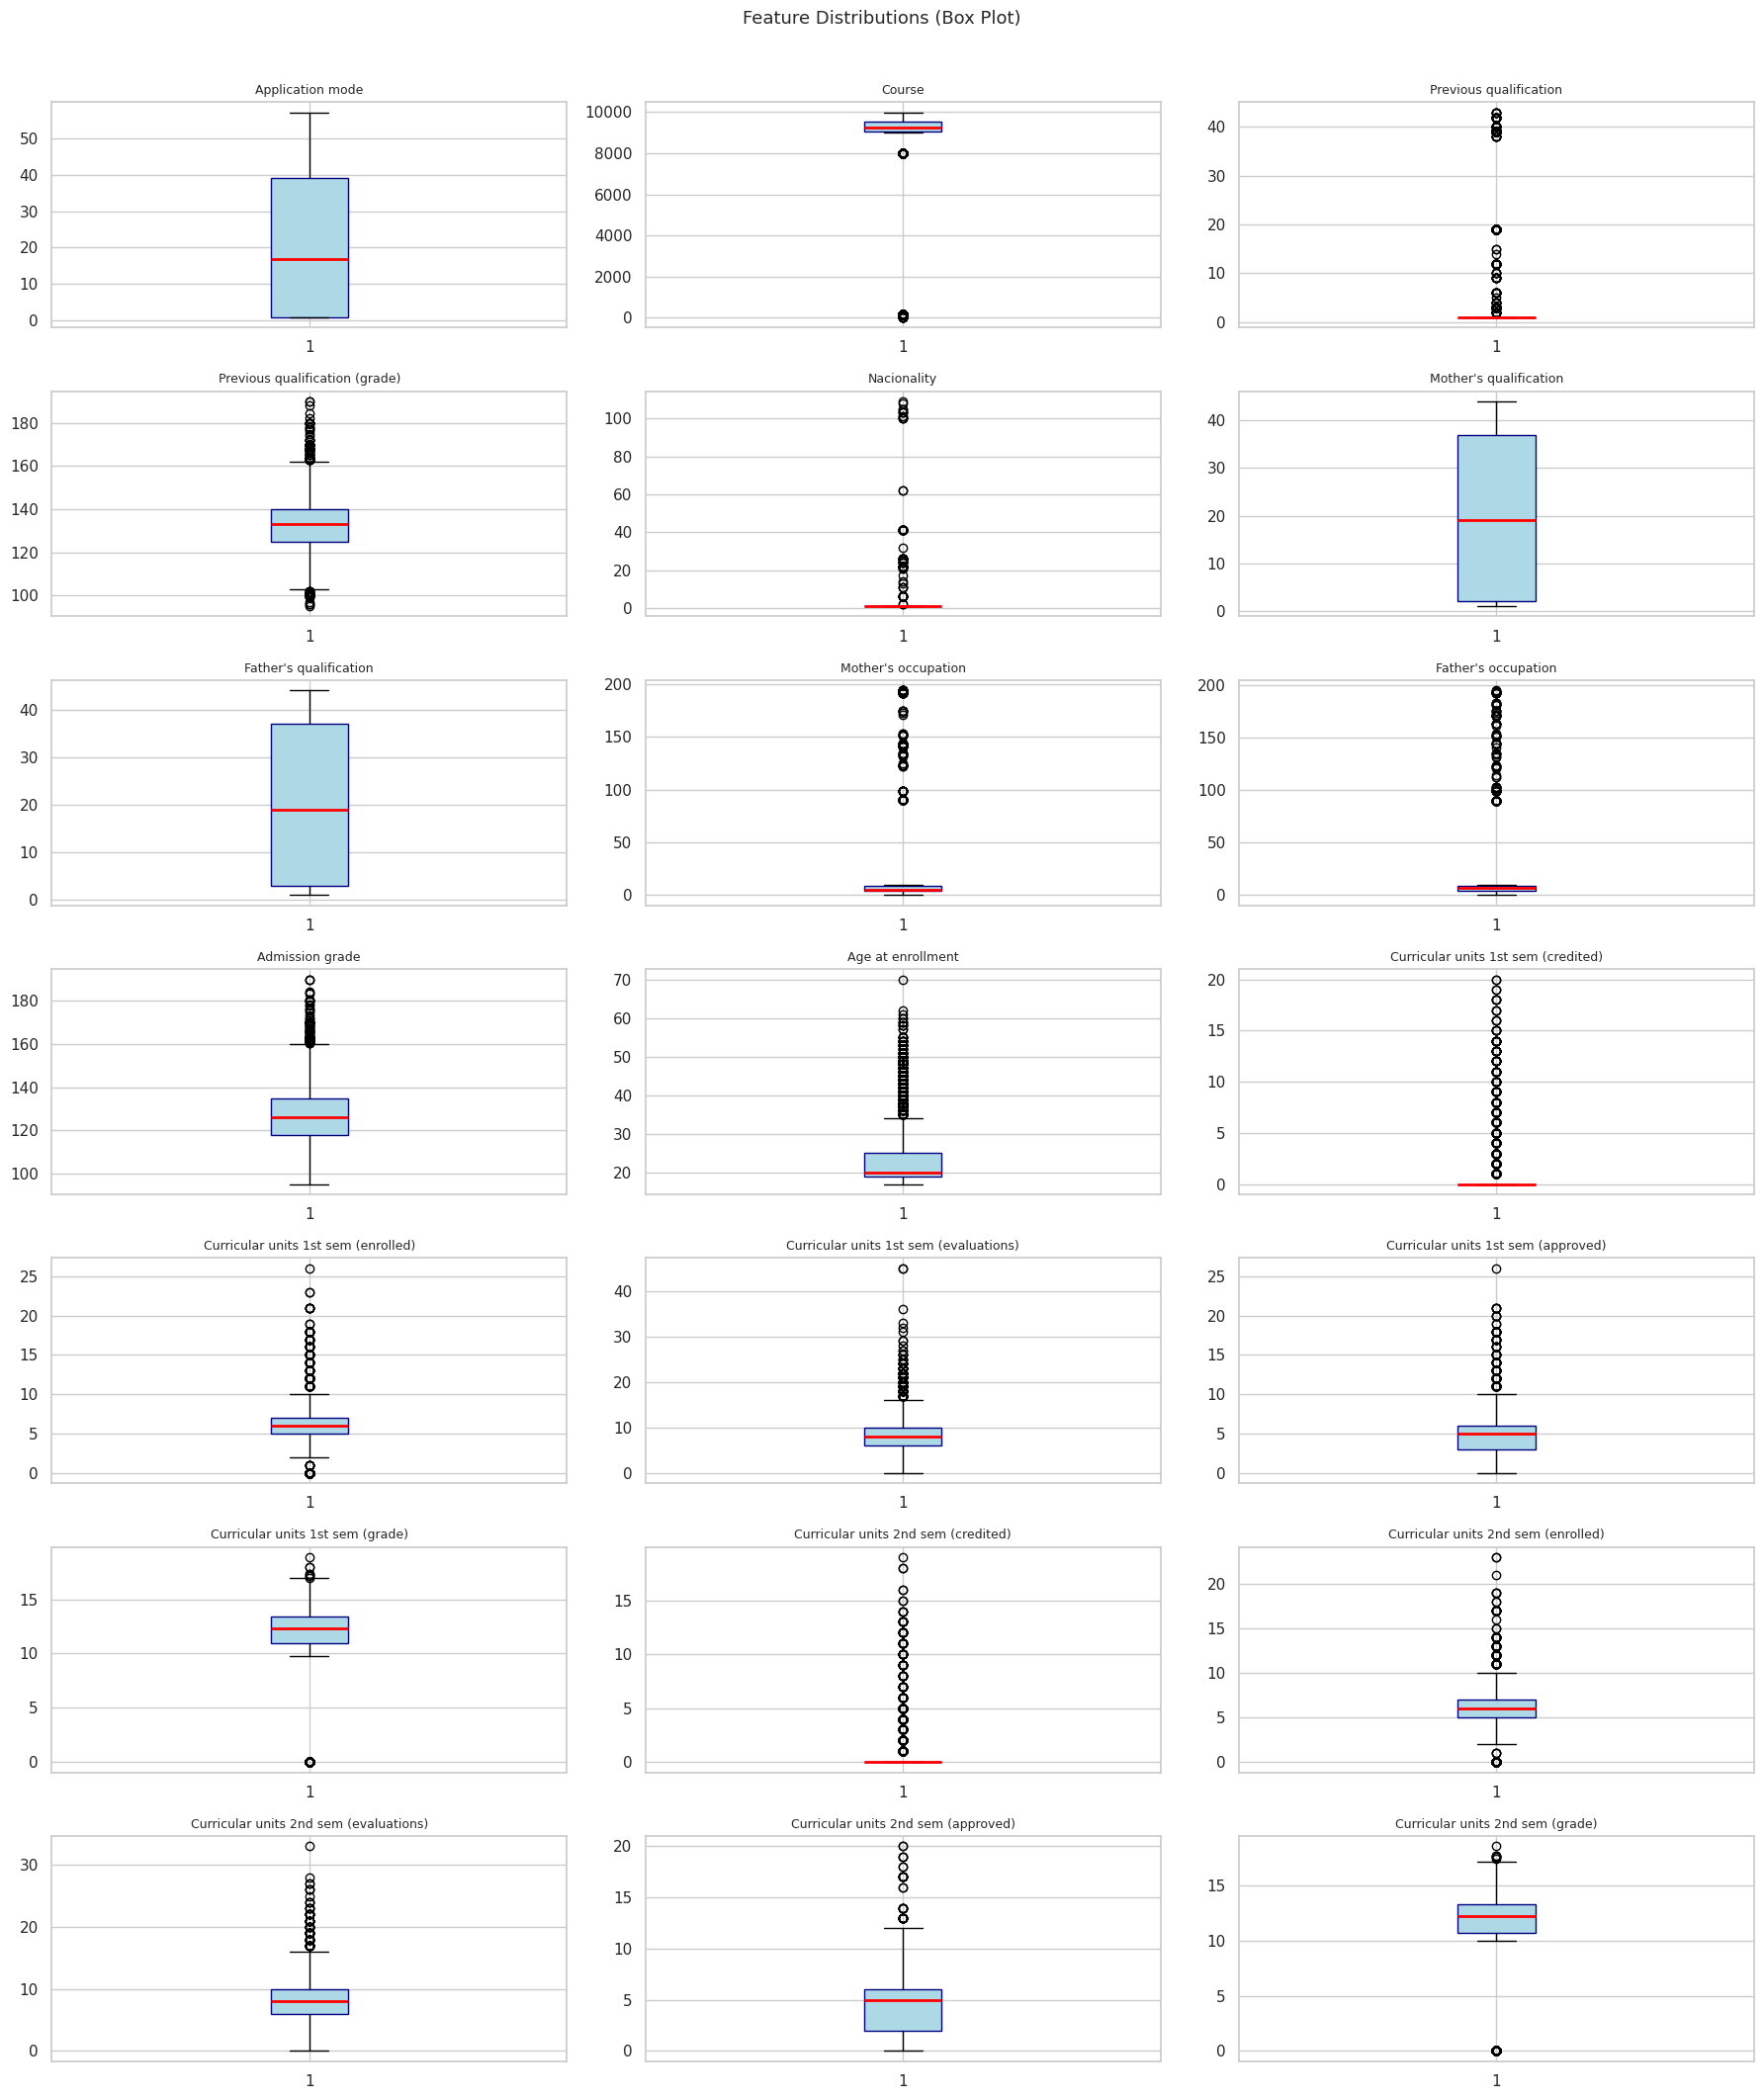

In [125]:
# Box plot (to visualize outliers)
if n > 0:
    fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 3))
    axes = axes.flatten()
    for i, col in enumerate(continuous_cols):
        axes[i].boxplot(df[col].dropna(), vert=True, patch_artist=True,
                        boxprops=dict(facecolor='lightblue', color='navy'),
                        medianprops=dict(color='red', linewidth=2))
        axes[i].set_title(f"{col}", fontsize=9)
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)
    plt.suptitle("Feature Distributions (Box Plot)", fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()

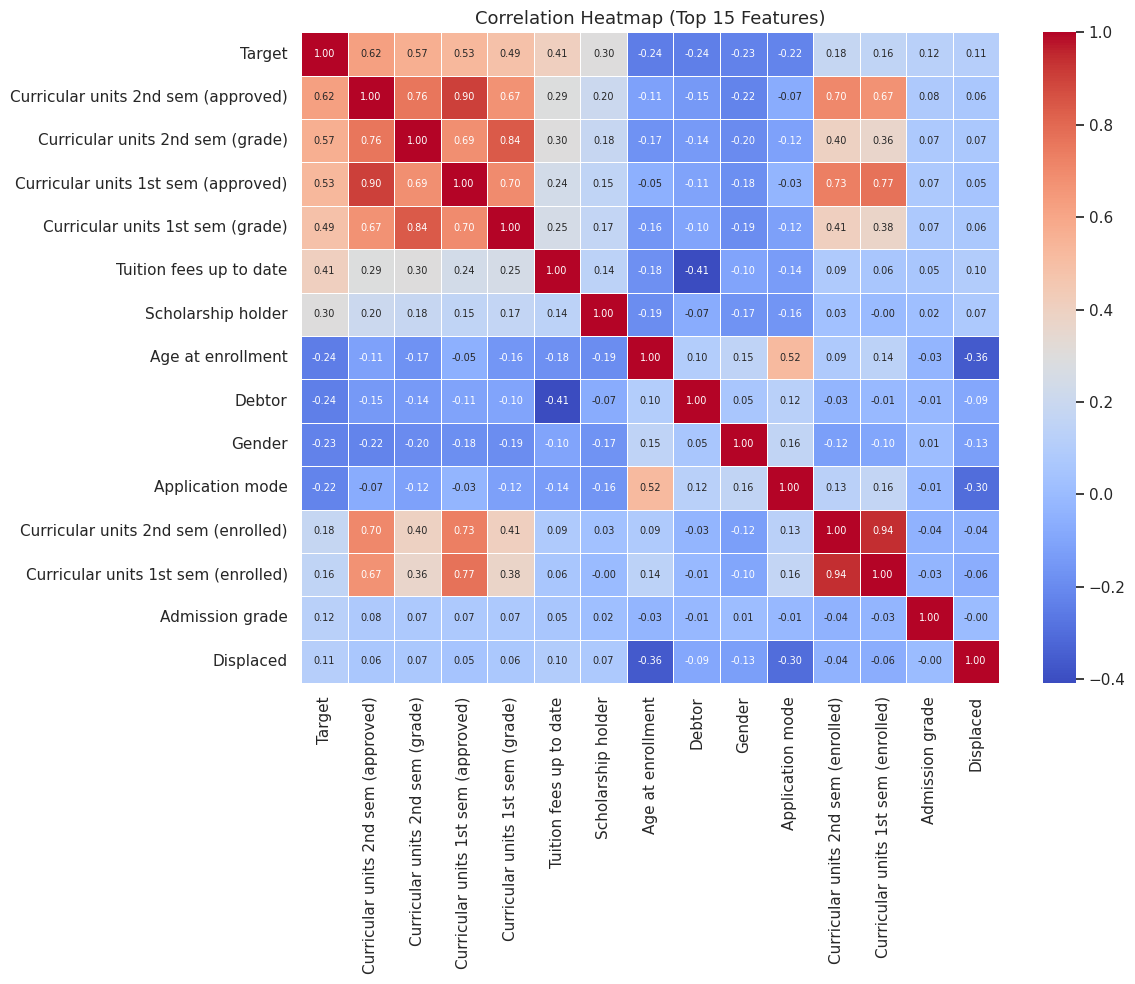

In [126]:
# Correlation heatmap (display top 15 features with highest correlation to Target)
top_features = corr_matrix["Target"].abs().sort_values(ascending=False).head(15).index.tolist() \
    if "Target" in corr_matrix.columns else list(df.columns[:15])

corr_sub = df[top_features].corr()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr_sub, annot=True, fmt=".2f", cmap="coolwarm",
            linewidths=0.5, ax=ax, annot_kws={"size": 7})
ax.set_title("Correlation Heatmap (Top 15 Features)", fontsize=13)
plt.tight_layout()
plt.show()

## 7. Export Processed Data

In [127]:
from sklearn.model_selection import train_test_split

ORIGINAL_TEST_SIZE = 0.3
ORIGINAL_RANDOM_STATE = 42

original_stratify = df["Target"] if "Target" in df.columns else None
org_train_df, org_test_df = train_test_split(
    df,
    test_size=ORIGINAL_TEST_SIZE,
    random_state=ORIGINAL_RANDOM_STATE,
    stratify=original_stratify,
    shuffle=True,
    )

os.makedirs(ORG_OUTPUT_DIR, exist_ok=True)
org_train_df.to_csv(ORG_OUTPUT_DIR / "train.csv", index=False)
org_test_df.to_csv(ORG_OUTPUT_DIR / "test.csv", index=False)

print("Original-method split sizes:")
print(f"  Train: {org_train_df.shape}")
print(f"  Test:  {org_test_df.shape}")
print(f"Saved original-method splits under: {ORG_OUTPUT_DIR}")

org_train_df.head()

Original-method split sizes:
  Train: (3096, 37)
  Test:  (1328, 37)
Saved original-method splits under: e:\Python\Machine-Learning-Project\data\processed_org


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
3742,1,17,1,9670,1,1,118.0000,1,19,38,7,9,113.5000,1,0,0,1,0,1,19,0,0,6,9,5,13.5000,0,0,6,6,6,14.0000,0,12.4000,0.5000,1.7900,2
3539,1,1,1,9070,1,1,139.0000,1,1,19,3,9,134.9000,1,0,0,1,1,0,20,0,0,6,7,6,13.6667,0,0,6,7,6,12.1667,1,16.2000,0.3000,-0.9200,2
1117,1,1,1,9500,1,1,138.0000,1,38,19,9,5,144.3000,0,0,0,1,0,0,20,0,0,7,9,6,12.7000,0,0,8,8,7,13.5714,0,13.9000,-0.3000,0.7900,2
790,1,17,1,9773,1,1,138.0000,1,1,19,9,9,124.0000,0,0,0,1,0,1,19,0,0,6,6,6,13.1667,0,0,6,6,6,13.8333,0,11.1000,0.6000,2.0200,2
4380,1,7,1,9500,1,2,140.0000,1,38,37,7,8,140.0000,0,0,0,1,0,0,29,0,0,8,14,4,11.3250,1,0,8,14,4,11.3250,1,12.7000,3.7000,-1.7000,0


## 8. Split-First Preprocessing With Train Statistics

Alternative preprocessing pipeline:
- Split the raw dataset into train/test first using a 70/30 ratio.
- Compute missing-value fill parameters from the training split only.
- Apply the training fill parameters to the test split.
- Use `pd.get_dummies` for one-hot encoding and align the test columns to the training feature space.

In [128]:
import os

import pandas as pd
from sklearn.model_selection import train_test_split

ALT_DATA_PATH = PROJECT_ROOT / "dataset" / "data.csv"
TARGET_COL = "Target"
TEST_SIZE = 0.3
RANDOM_STATE = 42
CATEGORICAL_COLUMNS = {
    "Marital status",
    "Application mode",
    "Application order",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International",
    }

raw_df = pd.read_csv(ALT_DATA_PATH, sep=';')
raw_df.columns = raw_df.columns.str.strip()
print(f"Raw dataset path: {ALT_DATA_PATH}")
print(f"Raw dataset shape: {raw_df.shape}")

stratify_labels = raw_df[TARGET_COL] if TARGET_COL in raw_df.columns else None
train_df, test_df = train_test_split(
    raw_df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=stratify_labels,
    shuffle=True,
    )

feature_cols = [col for col in raw_df.columns if col != TARGET_COL]
categorical_cols = [col for col in feature_cols if col in CATEGORICAL_COLUMNS]
numeric_cols = [col for col in feature_cols if col not in categorical_cols]

numeric_fill_values = train_df[numeric_cols].median()
categorical_fill_values = {}
for col in categorical_cols:
    mode_values = train_df[col].mode(dropna=True)
    categorical_fill_values[col] = mode_values.iloc[0] if not mode_values.empty else "Missing"

def preprocess_split(split_df, train_feature_columns=None):
    features = split_df[feature_cols].copy()

    if numeric_cols:
        features.loc[:, numeric_cols] = features[numeric_cols].fillna(numeric_fill_values)

    for col, fill_value in categorical_fill_values.items():
        features[col] = features[col].fillna(fill_value)

    encoded_features = pd.get_dummies(features, columns=categorical_cols, dtype=int)

    if train_feature_columns is not None:
        encoded_features = encoded_features.reindex(columns=train_feature_columns, fill_value=0)

    return encoded_features

X_train = preprocess_split(train_df)
train_feature_columns = X_train.columns.tolist()
X_test = preprocess_split(test_df, train_feature_columns=train_feature_columns)

y_train = train_df[TARGET_COL].reset_index(drop=True) if TARGET_COL in train_df.columns else None
y_test = test_df[TARGET_COL].reset_index(drop=True) if TARGET_COL in test_df.columns else None

train_processed = X_train.reset_index(drop=True)
test_processed = X_test.reset_index(drop=True)

if y_train is not None:
    train_processed[TARGET_COL] = y_train
    test_processed[TARGET_COL] = y_test

os.makedirs(ALT_OUTPUT_DIR, exist_ok=True)
train_processed.to_csv(ALT_OUTPUT_DIR / "train.csv", index=False)
test_processed.to_csv(ALT_OUTPUT_DIR / "test.csv", index=False)

print("Split sizes:")
print(f"  Train: {train_processed.shape}")
print(f"  Test:  {test_processed.shape}")
print(f"Categorical features one-hot encoded: {len(categorical_cols)}")
print(f"Encoded feature count: {len(train_feature_columns)}")
print(f"Missing values after preprocessing -> train: {train_processed.isna().sum().sum()}, test: {test_processed.isna().sum().sum()}")
print(f"Saved files under: {ALT_OUTPUT_DIR}")

train_processed.head()

Raw dataset path: e:\Python\Machine-Learning-Project\dataset\data.csv
Raw dataset shape: (4424, 37)
Split sizes:
  Train: (3096, 249)
  Test:  (1328, 249)
Categorical features one-hot encoded: 18
Encoded feature count: 248
Missing values after preprocessing -> train: 0, test: 0
Saved files under: e:\Python\Machine-Learning-Project\data\processed


,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Marital status_1,Marital status_2,Marital status_3,Marital status_4,Marital status_5,Marital status_6,Application mode_1,Application mode_2,Application mode_5,Application mode_7,Application mode_10,Application mode_15,Application mode_16,Application mode_17,Application mode_18,Application mode_26,Application mode_27,Application mode_39,Application mode_42,Application mode_43,Application mode_44,Application mode_51,Application mode_53,Application mode_57,Application order_0,Application order_1,Application order_2,Application order_3,Application order_4,Application order_5,Application order_6,Application order_9,Course_33,Course_171,Course_8014,Course_9003,Course_9070,Course_9085,Course_9119,Course_9130,Course_9147,Course_9238,Course_9254,Course_9500,Course_9556,Course_9670,Course_9773,Course_9853,Course_9991,Daytime/evening attendance_0,Daytime/evening attendance_1,Previous qualification_1,Previous qualification_2,Previous qualification_3,Previous qualification_4,Previous qualification_5,Previous qualification_6,Previous qualification_9,Previous qualification_10,Previous qualification_12,Previous qualification_14,Previous qualification_15,Previous qualification_19,Previous qualification_38,Previous qualification_39,Previous qualification_40,Previous qualification_42,Previous qualification_43,Nacionality_1,Nacionality_2,Nacionality_6,Nacionality_11,Nacionality_13,Nacionality_14,Nacionality_21,Nacionality_22,Nacionality_24,Nacionality_26,Nacionality_41,Nacionality_62,Nacionality_100,Nacionality_101,Nacionality_103,Nacionality_105,Nacionality_108,Mother's qualification_1,Mother's qualification_2,Mother's qualification_3,Mother's qualification_4,Mother's qualification_5,Mother's qualification_6,Mother's qualification_9,Mother's qualification_10,Mother's qualification_11,Mother's qualification_12,Mother's qualification_14,Mother's qualification_18,Mother's qualification_19,Mother's qualification_22,Mother's qualification_26,Mother's qualification_29,Mother's qualification_30,Mother's qualification_34,Mother's qualification_35,Mother's qualification_36,Mother's qualification_37,Mother's qualification_38,Mother's qualification_39,Mother's qualification_40,Mother's qualification_41,Mother's qualification_42,Mother's qualification_43,Mother's qualification_44,Father's qualification_1,Father's qualification_2,Father's qualification_3,Father's qualification_4,Father's qualification_5,Father's qualification_6,Father's qualification_9,Father's qualification_10,Father's qualification_11,Father's qualification_12,Father's qualification_14,Father's qualification_18,Father's qualification_19,Father's qualification_20,Father's qualification_22,Father's qualification_25,Father's qualification_26,Father's qualification_27,Father's qualification_29,Father's qualification_30,Father's qualification_31,Father's qualification_34,Father's qualification_35,Father's qualification_36,Father's qualification_37,Father's qualification_38,Father's qualification_39,Father's qualification_40,Father's qualification_41,Father's qualification_42,Father's qualification_43,Father's qualification_44,Mother's occupation_0,Mother's occupation_1,Mother's occupation_2,Mother's occupation_3,Mother's occupation_4,Mother's occupation_5,Mother's occupation_6,Mother's occupation_7,Mother's occupation_8,Mother's occupation_9,Mother's occupation_10,Mother's occupation_90,Mother's occupation_99,Mother's occupation_122,Mother's occupa

## 9. Save Fully One-Hot Encoded Full Dataset

Generate a single one-hot encoded dataframe from the full cleaned raw dataset and save it without train/val/test splitting.


In [129]:
import os
from pathlib import Path

FULLYONEHOT_OUTPUT_DIR = PROJECT_ROOT / "data" / "processed_fullyonehot"
FULLYONEHOT_FILE = FULLYONEHOT_OUTPUT_DIR / "fullyonehot.csv"

def build_fully_onehot_dataset(raw_df, target_col="Target", categorical_cols=None):
    features = raw_df.copy()
    if target_col not in features.columns:
        raise ValueError(f"Target column '{target_col}' not found in raw dataframe")

    feature_columns = [col for col in features.columns if col != target_col]
    all_categorical = set(categorical_cols or [])
    categorical_cols = [col for col in feature_columns if col in all_categorical]
    numeric_cols = [col for col in feature_columns if col not in all_categorical]

    filled = features[feature_columns].copy()

    if numeric_cols:
        numeric_fill = filled[numeric_cols].median()
        filled.loc[:, numeric_cols] = filled[numeric_cols].fillna(numeric_fill)

    for col in categorical_cols:
        mode_values = filled[col].mode(dropna=True)
        mode_value = mode_values.iloc[0] if not mode_values.empty else "Missing"
        filled[col] = filled[col].fillna(mode_value)

    encoded_features = pd.get_dummies(filled, columns=categorical_cols, dtype=int)
    encoded_features[target_col] = features[target_col].reset_index(drop=True)
    return encoded_features

full_onehot_df = build_fully_onehot_dataset(df, target_col=TARGET_COL, categorical_cols=CATEGORICAL_COLUMNS)

FULLYONEHOT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
full_onehot_df.to_csv(FULLYONEHOT_FILE, index=False)

print(f"Saved full one-hot dataset to: {FULLYONEHOT_FILE}")
print(f"Full one-hot shape: {full_onehot_df.shape}")
print(f"Total columns: {len(full_onehot_df.columns)}")
print("Target distribution:")
print(full_onehot_df[TARGET_COL].value_counts().sort_index().to_string())


Saved full one-hot dataset to: e:\Python\Machine-Learning-Project\data\processed_fullyonehot\fullyonehot.csv
Full one-hot shape: (4424, 262)
Total columns: 262
Target distribution:
Target
0    1421
1     794
2    2209


# Data Visualization with t-SNE

This notebook implements the Data Visualization section of the project. The goal is to project the high-dimensional Student Dropout dataset into 2D and 3D using t-SNE, then inspect whether the target classes show visible local structure.

Important interpretation rule: t-SNE is mainly for local-neighborhood visualization. Cluster sizes and long-range distances between clusters should be interpreted cautiously.


In [130]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OneHotEncoder, StandardScaler

plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.family"] = "DejaVu Sans"
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
print("Libraries loaded successfully.")


Libraries loaded successfully.


## 2. Load Processed Data

The preprocessed dataset has numeric features and an encoded target column. The target mapping from preprocessing is:

- `0`: Dropout
- `1`: Enrolled
- `2`: Graduate


In [131]:
DATA_PATH = Path("dataset/processed_data.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../dataset/processed_data.csv")

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()

target_map = {
    0: "Dropout",
    1: "Enrolled",
    2: "Graduate",
}

df["Target"] = df["Target"].astype(int)
df["Target Label"] = df["Target"].map(target_map)

print(f"Dataset shape: {df.shape}")
print("Target distribution:")
display(df["Target Label"].value_counts().rename_axis("Target").to_frame("Count"))
display(df.head())

Dataset shape: (4424, 38)
Target distribution:


,Count
Target,
Graduate,2209
Dropout,1421
Enrolled,794


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target,Target Label
0,1,17,5,171,1,1,122.0000,1,19,12,5,9,127.3000,1,0,0,1,1,0,20,0,0,0,0,0,0.0000,0,0,0,0,0,0.0000,0,10.8000,1.4000,1.7400,0,Dropout
1,1,15,1,9254,1,1,160.0000,1,1,3,3,3,142.5000,1,0,0,0,1,0,19,0,0,6,6,6,14.0000,0,0,6,6,6,13.6667,0,13.9000,-0.3000,0.7900,2,Graduate
2,1,1,5,9070,1,1,122.0000,1,37,37,9,9,124.8000,1,0,0,0,1,0,19,0,0,6,0,0,0.0000,0,0,6,0,0,0.0000,0,10.8000,1.4000,1.7400,0,Dropout
3,1,17,2,9773,1,1,122.0000,1,38,37,5,3,119.6000,1,0,0,1,0,0,20,0,0,6,8,6,13.4286,0,0,6,10,5,12.4000,0,9.4000,-0.8000,-3.1200,2,Graduate
4,2,39,1,8014,0,1,100.0000,1,37,38,9,9,141.5000,0,0,0,1,0,0,45,0,0,6,9,5,12.3333,0,0,6,6,6,13.0000,0,13.9000,-0.3000,0.7900,2,Graduate


## 3. Exploratory Findings Before t-SNE

Before interpreting the t-SNE map, the target balance and feature distributions should be checked. This gives context for what visual separation can realistically mean. In particular, class imbalance can make the largest class visually dominant, and integer-coded categorical columns should not be interpreted as continuous measurements.


,Target,Count,Percent
0,Graduate,2209,49.93%
1,Dropout,1421,32.12%
2,Enrolled,794,17.95%


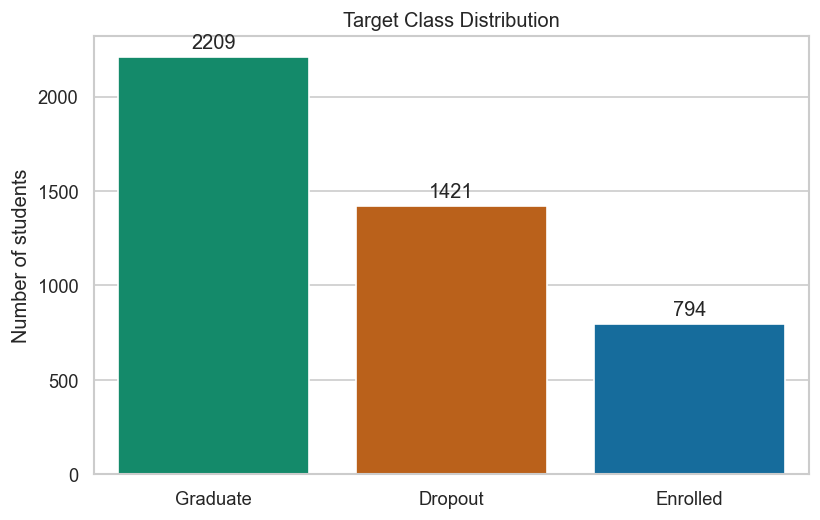

Missing values in processed data: 0


In [132]:
eda_palette = {
    "Dropout": "#d55e00",
    "Enrolled": "#0072b2",
    "Graduate": "#009e73",
}

target_counts = (
    df["Target Label"]
    .value_counts()
    .rename_axis("Target")
    .reset_index(name="Count")
)
target_counts["Percent"] = target_counts["Count"] / len(df) * 100

display(target_counts.style.format({"Percent": "{:.2f}%"}))

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(
    data=target_counts,
    x="Target",
    y="Count",
    hue="Target",
    hue_order=["Dropout", "Enrolled", "Graduate"],
    palette=eda_palette,
    legend=False,
    ax=ax,
)
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)
ax.set_title("Target Class Distribution")
ax.set_xlabel("")
ax.set_ylabel("Number of students")
plt.tight_layout()
plt.show()

missing_summary = df.drop(columns=["Target Label"]).isna().sum().sort_values(ascending=False)
print("Missing values in processed data:", int(missing_summary.sum()))


### 3.1 Feature-Target Relationship

The most interpretable features are inspected by target class before applying dimensionality reduction. Academic performance variables are expected to be especially informative because they directly summarize first- and second-semester progress.


,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),Curricular units 1st sem (grade),Curricular units 2nd sem (grade),Age at enrollment
Target Label,,,,,
Dropout,2.5500,1.9400,7.2600,5.9000,26.0700
Enrolled,4.3200,4.0600,11.1300,11.1200,22.3700
Graduate,6.2300,6.1800,12.6400,12.7000,21.7800


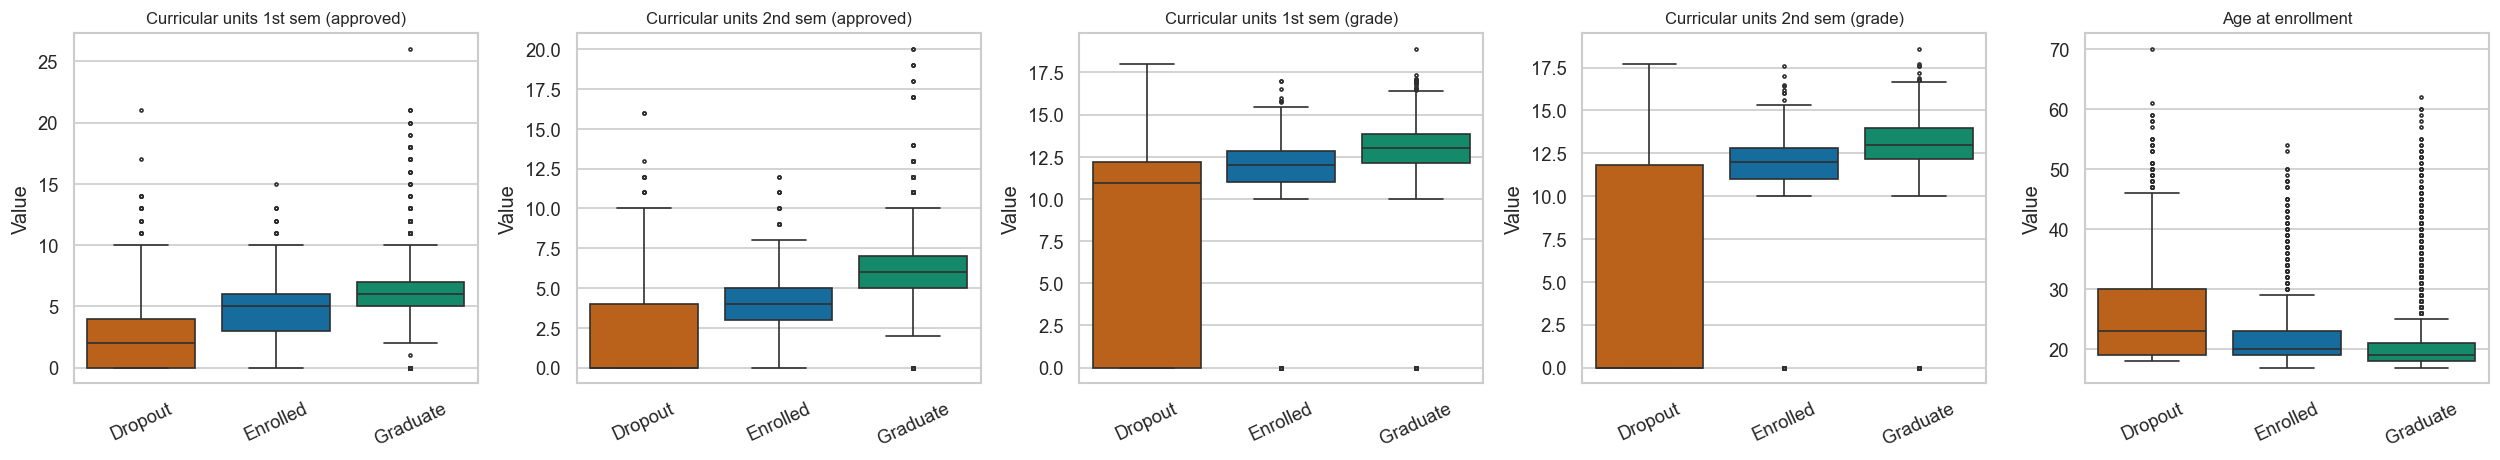

,Tuition fees up to date,Debtor,Scholarship holder,Gender
Target Label,,,,
Dropout,0.6780,0.2200,0.0940,0.4930
Enrolled,0.9470,0.1130,0.1640,0.3870
Graduate,0.9870,0.0460,0.3780,0.2480


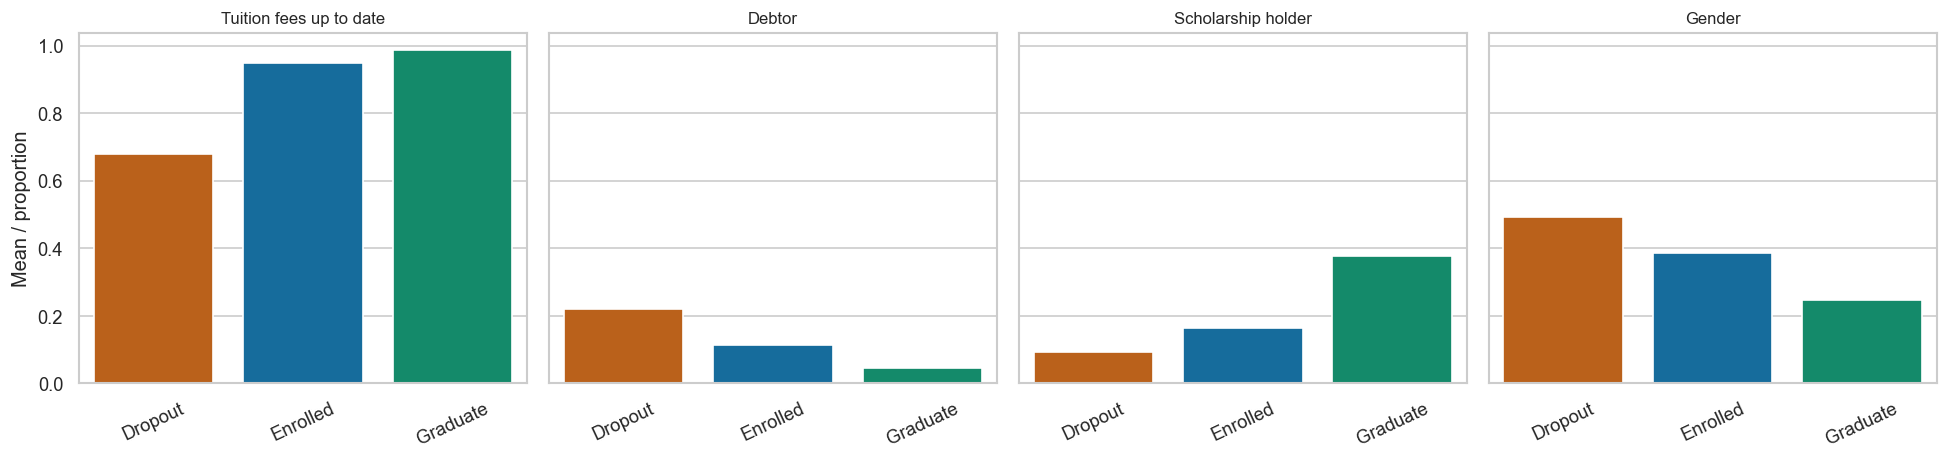

In [133]:
performance_features = [
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)",
    "Age at enrollment",
]
performance_features = [col for col in performance_features if col in df.columns]

profile_summary = (
    df.groupby("Target Label")[performance_features]
    .mean()
    .reindex(["Dropout", "Enrolled", "Graduate"])
)
display(profile_summary.round(2))

plot_df = df.melt(
    id_vars="Target Label",
    value_vars=performance_features,
    var_name="Feature",
    value_name="Value",
)
fig, axes = plt.subplots(1, len(performance_features), figsize=(4.2 * len(performance_features), 4), sharey=False)
if len(performance_features) == 1:
    axes = [axes]
for ax, feature in zip(axes, performance_features):
    sns.boxplot(
        data=plot_df[plot_df["Feature"] == feature],
        x="Target Label",
        y="Value",
        hue="Target Label",
        order=["Dropout", "Enrolled", "Graduate"],
        palette=eda_palette,
        legend=False,
        ax=ax,
        fliersize=1.8,
    )
    ax.set_title(feature, fontsize=10)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

binary_features = [
    "Tuition fees up to date",
    "Debtor",
    "Scholarship holder",
    "Gender",
]
binary_features = [col for col in binary_features if col in df.columns]
binary_rates = (
    df.groupby("Target Label")[binary_features]
    .mean()
    .reindex(["Dropout", "Enrolled", "Graduate"])
)
display(binary_rates.round(3))

fig, axes = plt.subplots(1, len(binary_features), figsize=(4.1 * len(binary_features), 4), sharey=True)
if len(binary_features) == 1:
    axes = [axes]
for ax, feature in zip(axes, binary_features):
    sns.barplot(
        data=df,
        x="Target Label",
        y=feature,
        hue="Target Label",
        order=["Dropout", "Enrolled", "Graduate"],
        palette=eda_palette,
        legend=False,
        errorbar=None,
        ax=ax,
    )
    ax.set_title(feature, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Mean / proportion")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


### 3.2 Academic Performance Block Redundancy

Before compressing features, we first check whether the academic performance variables contain repeated information. The first- and second-semester curricular-unit measures are expected to describe related student progress, so high pairwise correlations would justify using compact feature engineering rather than listing every semester-specific variable separately.


,Feature 1,Feature 2,Abs correlation
0,Curricular units 1st sem (credited),Curricular units 2nd sem (credited),0.9448
1,Curricular units 1st sem (enrolled),Curricular units 2nd sem (enrolled),0.9426
2,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),0.9040
3,Curricular units 1st sem (grade),Curricular units 2nd sem (grade),0.8372
4,Curricular units 1st sem (evaluations),Curricular units 2nd sem (evaluations),0.7789
5,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),0.7743
6,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),0.7691
7,Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),0.7608
8,Curricular units 2nd sem (credited),Curricular units 1st sem (enrolled),0.7537
9,Curricular units 2nd sem (enrolled),Curricular units 1st sem (approved),0.7338


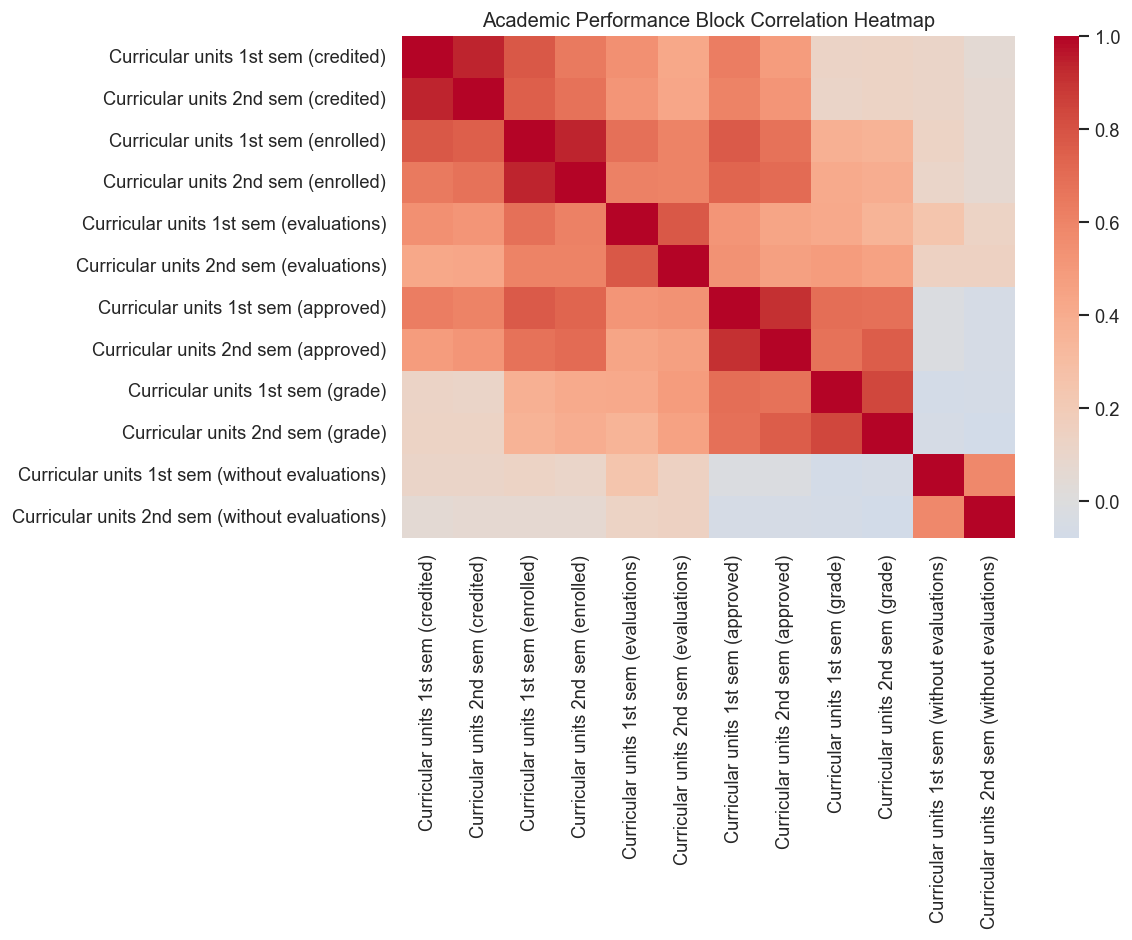

In [134]:
academic_block_features = [
    "Curricular units 1st sem (credited)",
    "Curricular units 2nd sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 2nd sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 1st sem (without evaluations)",
    "Curricular units 2nd sem (without evaluations)",
]
academic_block_features = [col for col in academic_block_features if col in df.columns]

academic_corr = df[academic_block_features].corr(numeric_only=True)
academic_pair_rows = []
for i, feature_a in enumerate(academic_block_features):
    for feature_b in academic_block_features[i + 1:]:
        academic_pair_rows.append(
            {
                "Feature 1": feature_a,
                "Feature 2": feature_b,
                "Abs correlation": abs(academic_corr.loc[feature_a, feature_b]),
            }
        )

top_academic_pairwise_corr = (
    pd.DataFrame(academic_pair_rows)
    .sort_values("Abs correlation", ascending=False)
    .head(12)
    .reset_index(drop=True)
)
display(top_academic_pairwise_corr.round(4))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    academic_corr,
    cmap="coolwarm",
    center=0,
    ax=ax,
)
ax.set_title("Academic Performance Block Correlation Heatmap")
plt.tight_layout()
plt.show()



### 3.3 Compact Average-Based Feature Screening

The first compression method is an interpretable average-based summary. Paired first- and second-semester curricular-unit features are averaged into composite variables before computing correlation with the encoded target. This keeps the correlation ranking readable and highlights feature families such as average approved units and average grades, but it is still only an exploratory screening tool rather than causal evidence.


,Correlation with Target
Average curricular units approved,0.5904
Average curricular units grade,0.5504
Tuition fees up to date,0.4098
Scholarship holder,0.2976
Age at enrollment,-0.2434
Debtor,-0.2410
Gender,-0.2293
Application mode,-0.2217
Average curricular units enrolled,0.1677
Admission grade,0.1209


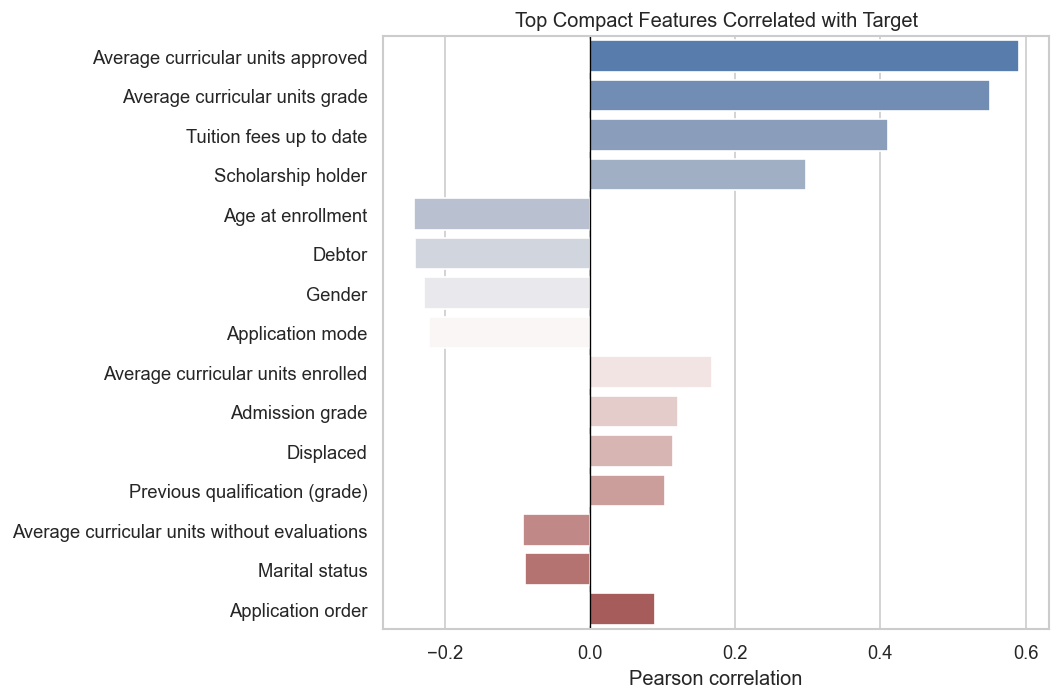

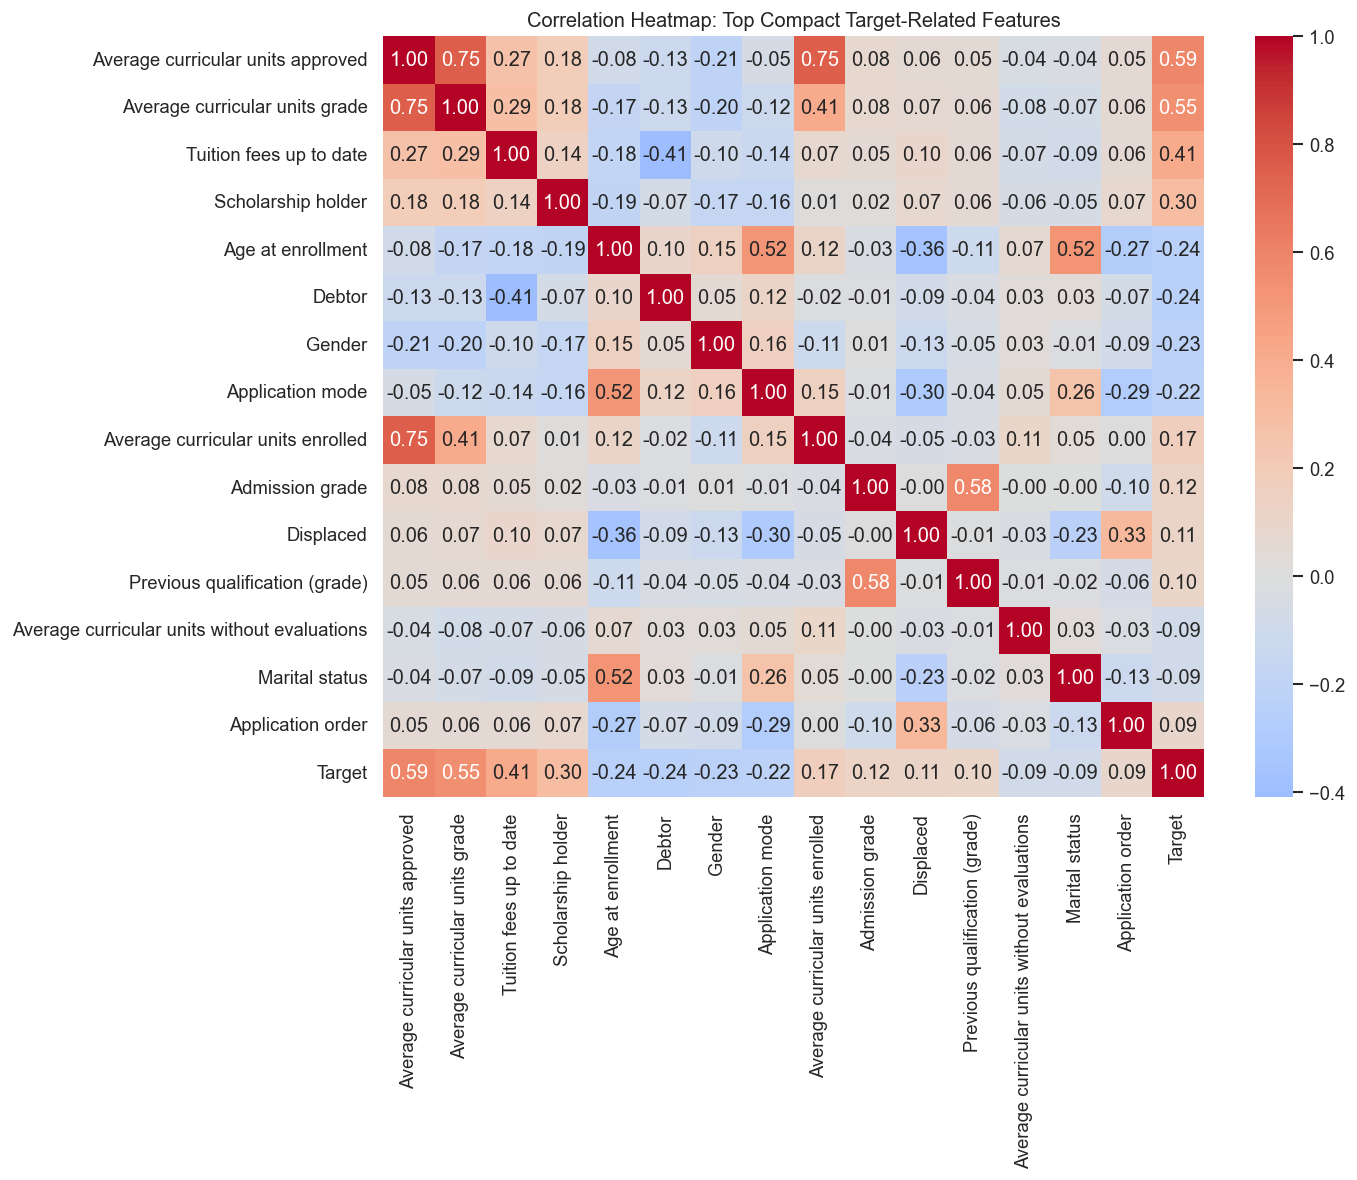

In [135]:
semester_feature_pairs = {
    "Average curricular units approved": [
        "Curricular units 1st sem (approved)",
        "Curricular units 2nd sem (approved)",
    ],
    "Average curricular units grade": [
        "Curricular units 1st sem (grade)",
        "Curricular units 2nd sem (grade)",
    ],
    "Average curricular units enrolled": [
        "Curricular units 1st sem (enrolled)",
        "Curricular units 2nd sem (enrolled)",
    ],
    "Average curricular units evaluations": [
        "Curricular units 1st sem (evaluations)",
        "Curricular units 2nd sem (evaluations)",
    ],
    "Average curricular units credited": [
        "Curricular units 1st sem (credited)",
        "Curricular units 2nd sem (credited)",
    ],
    "Average curricular units without evaluations": [
        "Curricular units 1st sem (without evaluations)",
        "Curricular units 2nd sem (without evaluations)",
    ],
}

compact_corr_df = df.drop(columns=["Target Label"]).copy()
paired_semester_columns = set()

for composite_name, source_columns in semester_feature_pairs.items():
    available_columns = [col for col in source_columns if col in compact_corr_df.columns]
    if available_columns:
        compact_corr_df[composite_name] = compact_corr_df[available_columns].mean(axis=1)
        paired_semester_columns.update(available_columns)

compact_corr_df = compact_corr_df.drop(columns=sorted(paired_semester_columns))

compact_corr_matrix = compact_corr_df.corr(numeric_only=True)
compact_target_corr = (
    compact_corr_matrix["Target"]
    .drop("Target")
    .sort_values(key=lambda values: values.abs(), ascending=False)
)
top_compact_target_corr = compact_target_corr.head(15).rename("Correlation with Target").to_frame()
display(top_compact_target_corr.round(4))

fig, ax = plt.subplots(figsize=(9, 6))
plot_corr = top_compact_target_corr.reset_index().rename(columns={"index": "Feature"})
sns.barplot(
    data=plot_corr,
    y="Feature",
    x="Correlation with Target",
    hue="Feature",
    palette="vlag",
    legend=False,
    ax=ax,
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Top Compact Features Correlated with Target")
ax.set_xlabel("Pearson correlation")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

heatmap_features = top_compact_target_corr.index.tolist() + ["Target"]
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    compact_corr_df[heatmap_features].corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=ax,
)
ax.set_title("Correlation Heatmap: Top Compact Target-Related Features")
plt.tight_layout()
plt.show()


### 3.4 PCA-Based Academic Feature Compression

The second compression method is PCA on the academic performance block. Unlike simple averages, PCA creates orthogonal components that can preserve multiple directions of academic-performance variation. This makes it more suitable as a downstream modeling candidate when multicollinearity is a concern. If PCA features are later used in supervised models, PCA should be fitted on the training split and then applied to validation/test data to avoid data leakage.


,Component,Explained variance ratio,Cumulative explained variance
0,Academic_PC1,0.5138,0.5138
1,Academic_PC2,0.1698,0.6836
2,Academic_PC3,0.1227,0.8063
3,Academic_PC4,0.0668,0.8730
4,Academic_PC5,0.0358,0.9088
5,Academic_PC6,0.0343,0.9431


,Correlation with Target
Academic_PC1,0.3458
Academic_PC2,0.4625
Academic_PC3,0.1212
Academic_PC4,-0.3525
Academic_PC5,0.0683
Academic_PC6,-0.0470


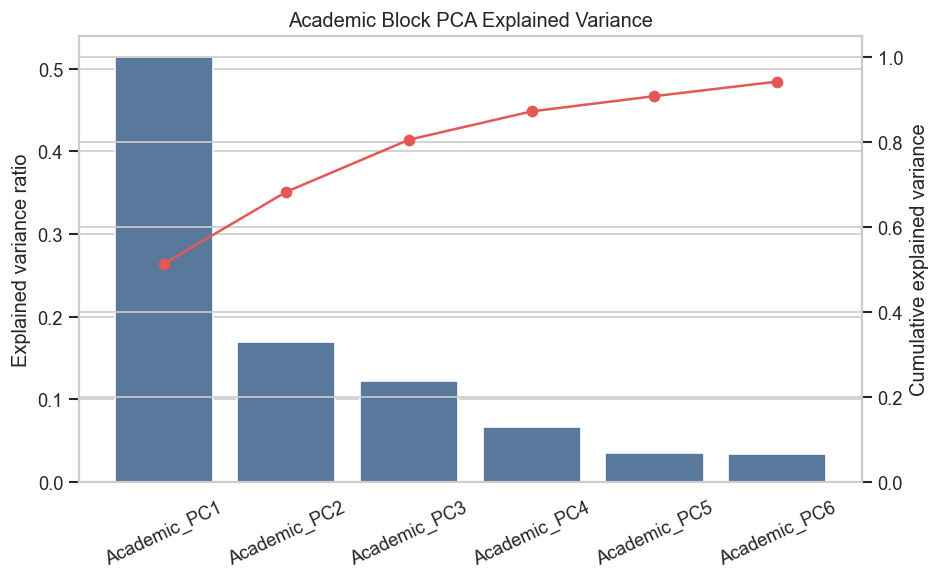

In [136]:
academic_block_filled = df[academic_block_features].fillna(df[academic_block_features].median())
academic_block_scaled = StandardScaler().fit_transform(academic_block_filled)
academic_pca = PCA(n_components=min(6, len(academic_block_features)), random_state=RANDOM_STATE)
academic_pca_scores = academic_pca.fit_transform(academic_block_scaled)
academic_pca_df = pd.DataFrame(
    academic_pca_scores,
    columns=[f"Academic_PC{i + 1}" for i in range(academic_pca_scores.shape[1])],
)
academic_pca_df["Target"] = df["Target"].values


academic_pca_variance = pd.DataFrame(
    {
        "Component": [f"Academic_PC{i + 1}" for i in range(len(academic_pca.explained_variance_ratio_))],
        "Explained variance ratio": academic_pca.explained_variance_ratio_,
        "Cumulative explained variance": academic_pca.explained_variance_ratio_.cumsum(),
    }
)
display(academic_pca_variance.round(4))

academic_pc_target_corr = (
    academic_pca_df.corr(numeric_only=True)["Target"]
    .drop("Target")
    .rename("Correlation with Target")
    .to_frame()
)
display(academic_pc_target_corr.round(4))

fig, ax1 = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=academic_pca_variance,
    x="Component",
    y="Explained variance ratio",
    color="#4C78A8",
    ax=ax1,
)
ax1.set_title("Academic Block PCA Explained Variance")
ax1.set_xlabel("")
ax1.set_ylabel("Explained variance ratio")
ax1.tick_params(axis="x", rotation=25)
ax2 = ax1.twinx()
ax2.plot(
    academic_pca_variance["Component"],
    academic_pca_variance["Cumulative explained variance"],
    color="#E45756",
    marker="o",
)
ax2.set_ylabel("Cumulative explained variance")
ax2.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()


## 4. Prepare Features for t-SNE

`Target` is excluded from the input features and used only for coloring the plots. The dataset contains both encoded categorical variables and continuous numeric variables. For a more rigorous distance-based visualization, categorical variables are one-hot encoded while continuous and ordinal numeric variables are standardized.


In [137]:
feature_cols = [col for col in df.columns if col not in ["Target", "Target Label"]]
X = df[feature_cols].copy()
y = df["Target"].copy()
y_label = df["Target Label"].copy()

# These columns are integer-coded categories in the original dataset, not continuous quantities.
categorical_feature_cols = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International",
]
categorical_feature_cols = [col for col in categorical_feature_cols if col in X.columns]
numeric_feature_cols = [col for col in X.columns if col not in categorical_feature_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_feature_cols),
        ("numeric", StandardScaler(), numeric_feature_cols),
    ],
    verbose_feature_names_out=False,
)

X_prepared = preprocessor.fit_transform(X)

print(f"Number of samples: {X_prepared.shape[0]}")
print(f"Original input features before encoding: {len(feature_cols)}")
print(f"t-SNE input features after one-hot encoding and scaling: {X_prepared.shape[1]}")
print("Categorical features one-hot encoded:", len(categorical_feature_cols))
print("Numeric/ordinal features standardized:", len(numeric_feature_cols))
print("Target excluded from feature matrix:", "Target" not in feature_cols)

Number of samples: 4424
Original input features before encoding: 36
t-SNE input features after one-hot encoding and scaling: 255
Categorical features one-hot encoded: 17
Numeric/ordinal features standardized: 19
Target excluded from feature matrix: True


## 5. Helper Plotting Functions


In [ ]:
palette = {
    "Dropout": "#d55e00",
    "Enrolled": "#0072b2",
    "Graduate": "#009e73",
}
1
def make_tsne(n_components=2, perplexity=30):
    model = TSNE(
        n_components=n_components,
        perplexity=perplexity,
        learning_rate="auto",
        init="pca",
        random_state=RANDOM_STATE,
    )
    return model.fit_transform(X_prepared)

def embedding_frame(embedding, prefix="TSNE"):
    data = pd.DataFrame(embedding, columns=[f"{prefix}{i + 1}" for i in range(embedding.shape[1])])
    data["Target"] = y.values
    data["Target Label"] = y_label.values
    return data

def plot_tsne_2d(data, title, ax=None, legend=True):
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))
    sns.scatterplot(
        data=data,
        x="TSNE1",
        y="TSNE2",
        hue="Target Label",
        hue_order=["Dropout", "Enrolled", "Graduate"],
        palette=palette,
        s=18,
        alpha=0.75,
        linewidth=0,
        ax=ax,
        legend=legend,
    )
    ax.set_title(title)
    ax.set_xlabel("t-SNE dimension 1")
    ax.set_ylabel("t-SNE dimension 2")
    if legend:
        ax.legend(title="Target", loc="best", frameon=True)
    return ax

def knn_label_agreement(points, labels, n_neighbors=15):
    neighbors = NearestNeighbors(n_neighbors=n_neighbors + 1).fit(points)
    neighbor_indices = neighbors.kneighbors(return_distance=False)[:, 1:]
    return (labels[neighbor_indices] == labels[:, None]).mean()

def random_same_label_baseline(labels):
    proportions = pd.Series(labels).value_counts(normalize=True)
    return float((proportions ** 2).sum())

def evaluate_embedding(name, embedding, n_neighbors=15):
    labels = y.to_numpy()
    return {
        "Embedding": name,
        "Dimensions": embedding.shape[1],
        "Silhouette by Target": silhouette_score(embedding, labels),
        "Davies-Bouldin by Target": davies_bouldin_score(embedding, labels),
        f"Trustworthiness@{n_neighbors}": trustworthiness(X_prepared, embedding, n_neighbors=n_neighbors),
        f"KNN Label Agreement@{n_neighbors}": knn_label_agreement(embedding, labels, n_neighbors=n_neighbors),
    }

## 6. PCA Baseline Projection

PCA is added as a linear baseline before t-SNE. If PCA already separates the classes clearly, the dominant structure is mostly linear. If PCA is mixed while t-SNE shows local grouping, the useful structure is more local or nonlinear.


PCA explained variance: PC1=0.234, PC2=0.097, total=0.331


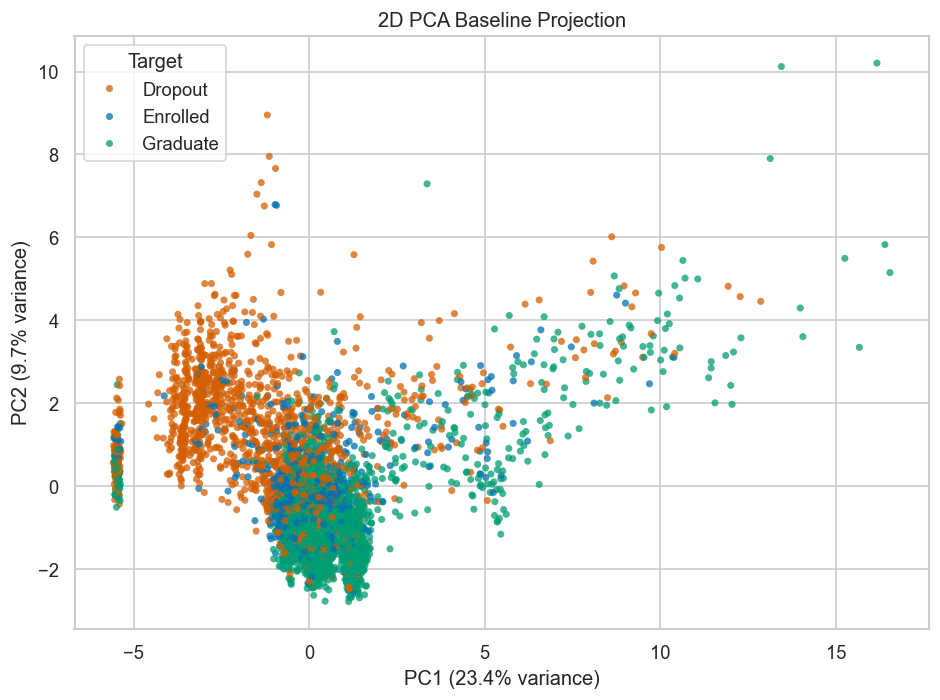

,Embedding,Dimensions,Silhouette by Target,Davies-Bouldin by Target,Trustworthiness@15,KNN Label Agreement@15
0,2D PCA baseline,2,0.0032,2.9621,0.8021,0.5872


In [139]:
pca_model = PCA(n_components=2, random_state=RANDOM_STATE)
pca_2d = pca_model.fit_transform(X_prepared)
pca_df = pd.DataFrame(pca_2d, columns=["PC1", "PC2"])
pca_df["Target"] = y.values
pca_df["Target Label"] = y_label.values

explained = pca_model.explained_variance_ratio_
print(f"PCA explained variance: PC1={explained[0]:.3f}, PC2={explained[1]:.3f}, total={explained.sum():.3f}")

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Target Label",
    hue_order=["Dropout", "Enrolled", "Graduate"],
    palette=palette,
    s=18,
    alpha=0.75,
    linewidth=0,
    ax=ax,
)
ax.set_title("2D PCA Baseline Projection")
ax.set_xlabel(f"PC1 ({explained[0] * 100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({explained[1] * 100:.1f}% variance)")
ax.legend(title="Target", loc="best", frameon=True)
plt.tight_layout()
plt.show()

pca_metrics = evaluate_embedding("2D PCA baseline", pca_2d, n_neighbors=15)
display(pd.DataFrame([pca_metrics]).round(4))


## 7. Main 2D t-SNE Projection

`perplexity=30` is used as the main setting because it balances local and broader neighborhood structure for a dataset of this size.


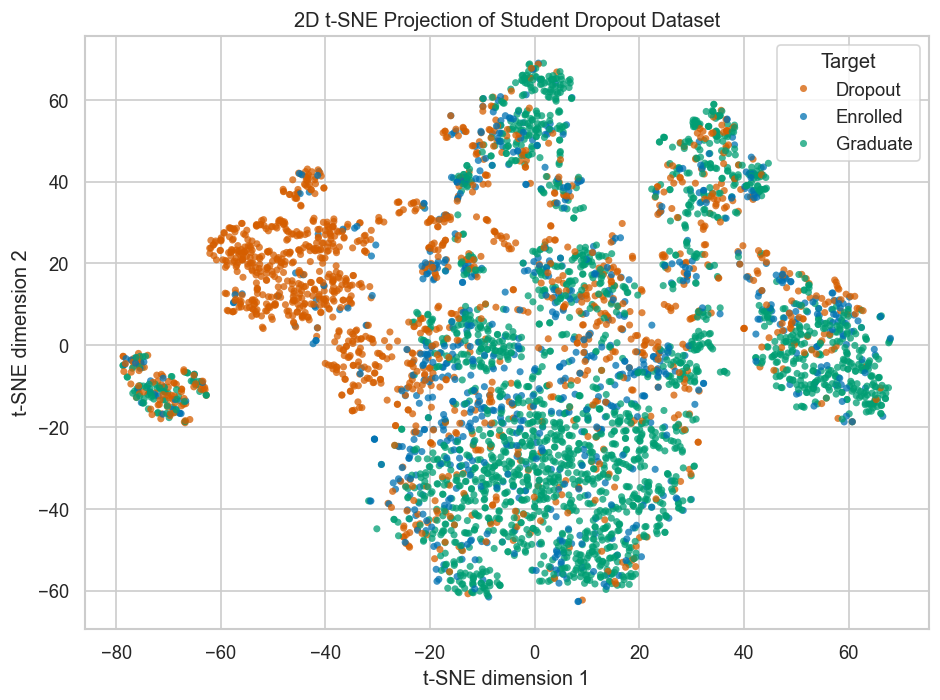

,TSNE1,TSNE2,Target,Target Label
0,-66.6877,-14.2938,0,Dropout
1,17.5011,-25.5997,2,Graduate
2,-59.9991,25.7577,0,Dropout
3,-4.8275,52.7937,2,Graduate
4,7.1604,20.8601,2,Graduate


In [140]:
tsne_2d = make_tsne(n_components=2, perplexity=30)
tsne_2d_df = embedding_frame(tsne_2d)

fig, ax = plt.subplots(figsize=(8, 6))
plot_tsne_2d(tsne_2d_df, "2D t-SNE Projection of Student Dropout Dataset", ax=ax)
plt.tight_layout()
plt.show()

display(tsne_2d_df.head())

## 8. 3D t-SNE Projection

The 3D view provides an additional perspective on local class separation. It should be used as supporting evidence rather than a replacement for quantitative model evaluation.


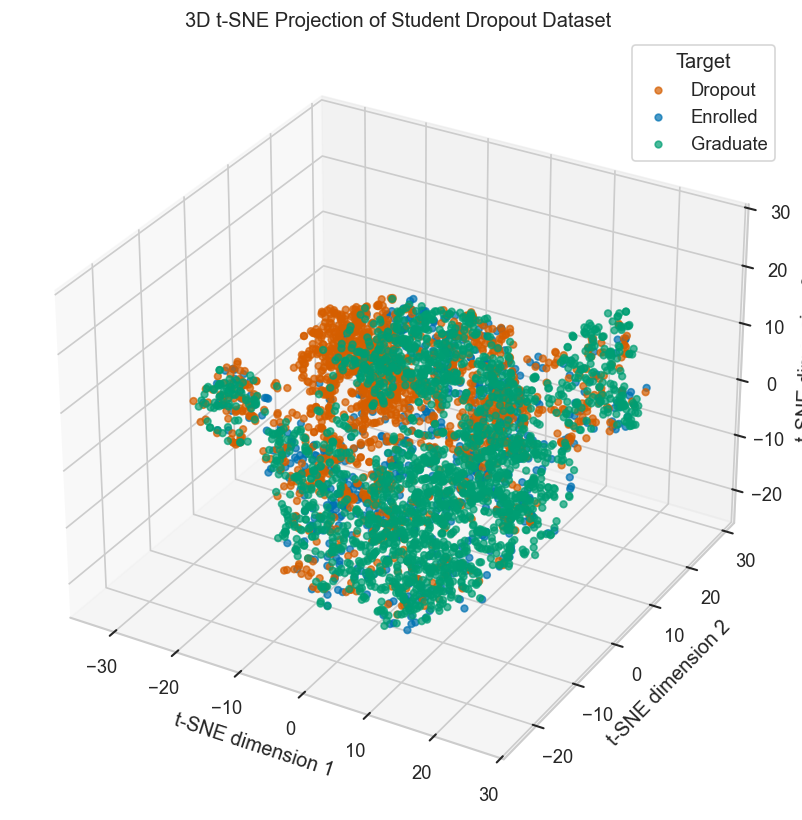

In [141]:
tsne_3d = make_tsne(n_components=3, perplexity=30)
tsne_3d_df = embedding_frame(tsne_3d)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

for label in ["Dropout", "Enrolled", "Graduate"]:
    subset = tsne_3d_df[tsne_3d_df["Target Label"] == label]
    ax.scatter(
        subset["TSNE1"],
        subset["TSNE2"],
        subset["TSNE3"],
        label=label,
        s=16,
        alpha=0.7,
        color=palette[label],
    )

ax.set_title("3D t-SNE Projection of Student Dropout Dataset")
ax.set_xlabel("t-SNE dimension 1")
ax.set_ylabel("t-SNE dimension 2")
ax.set_zlabel("t-SNE dimension 3")
ax.legend(title="Target", loc="best")
plt.tight_layout()
plt.show()

## 9. Perplexity Sensitivity Analysis

Perplexity controls the effective number of neighbors used by t-SNE. Lower values emphasize very local structure; higher values incorporate broader neighborhood information. The visual pattern should be checked under multiple settings before drawing conclusions.


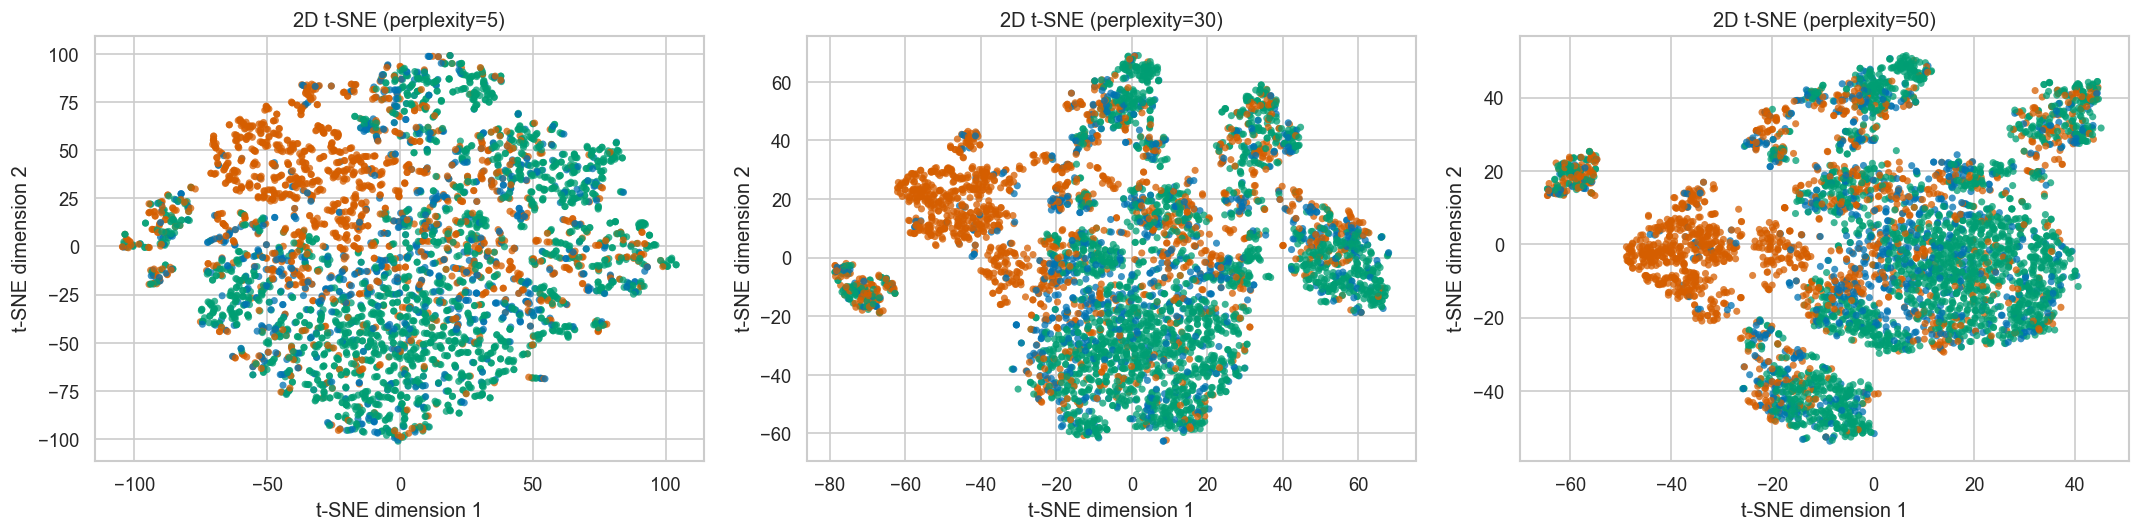

In [142]:
perplexities = [5, 30, 50]
tsne_embeddings_2d = {30: tsne_2d}

fig, axes = plt.subplots(1, len(perplexities), figsize=(18, 5), sharex=False, sharey=False)

for ax, perplexity in zip(axes, perplexities):
    if perplexity not in tsne_embeddings_2d:
        tsne_embeddings_2d[perplexity] = make_tsne(n_components=2, perplexity=perplexity)
    embedding = tsne_embeddings_2d[perplexity]
    data = embedding_frame(embedding)
    plot_tsne_2d(
        data,
        title=f"2D t-SNE (perplexity={perplexity})",
        ax=ax,
        legend=False,
    )

handles, labels = axes[-1].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, title="Target", loc="upper center", ncol=3, frameon=True)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

## 10. Auxiliary Quality Metrics

These metrics do not replace visual inspection, but they make the interpretation more rigorous.

- `Trustworthiness`: how well local neighborhoods from the high-dimensional data are preserved in the embedding. Higher is better.
- `Silhouette by Target`: how separated the target classes are in the embedding. Values near 0 indicate overlapping classes.
- `Davies-Bouldin by Target`: another class-separation metric. Lower is better.
- `KNN Label Agreement`: the fraction of nearest neighbors in the embedding that share the same target label. Compare it with the random same-label baseline.


In [143]:
N_NEIGHBORS = 15
metrics_rows = []

for perplexity in perplexities:
    metrics_rows.append(
        evaluate_embedding(
            name=f"2D t-SNE perplexity={perplexity}",
            embedding=tsne_embeddings_2d[perplexity],
            n_neighbors=N_NEIGHBORS,
        )
    )

metrics_rows.append(
    evaluate_embedding(
        name="3D t-SNE perplexity=30",
        embedding=tsne_3d,
        n_neighbors=N_NEIGHBORS,
    )
)

metrics_df = pd.DataFrame(metrics_rows)

baseline_df = pd.DataFrame(
    {
        "Metric": [
            f"Prepared-space KNN Label Agreement@{N_NEIGHBORS}",
            "Random Same-Label Baseline",
        ],
        "Value": [
            knn_label_agreement(X_prepared, y.to_numpy(), n_neighbors=N_NEIGHBORS),
            random_same_label_baseline(y.to_numpy()),
        ],
    }
)

display(metrics_df.round(4))
display(baseline_df.round(4))

,Embedding,Dimensions,Silhouette by Target,Davies-Bouldin by Target,Trustworthiness@15,KNN Label Agreement@15
0,2D t-SNE perplexity=5,2,0.0028,6.8439,0.9569,0.5766
1,2D t-SNE perplexity=30,2,0.0157,5.9765,0.9716,0.5848
2,2D t-SNE perplexity=50,2,0.0227,5.4834,0.9725,0.5916
3,3D t-SNE perplexity=30,3,0.0236,6.2556,0.9787,0.5918


,Metric,Value
0,Prepared-space KNN Label Agreement@15,0.6174
1,Random Same-Label Baseline,0.3847


## 11. Discussion

The t-SNE visualization should be interpreted as a local-neighborhood map of students with similar enrollment, demographic, socioeconomic, and semester-performance characteristics. If `Graduate` points form visibly dense regions, this suggests that successful students share similar feature profiles in the prepared input space. If `Dropout` and `Enrolled` points overlap with other classes, this indicates that their profiles are less cleanly separated by visualization alone and may require supervised models or additional feature engineering for stronger discrimination.

The auxiliary metrics should be interpreted together with the plots. High trustworthiness supports that the embedding preserves local neighborhoods. However, near-zero silhouette scores or high Davies-Bouldin scores would indicate that the target classes are still substantially overlapping in the t-SNE space. The perplexity comparison is part of the interpretation. Stable class patterns across `perplexity=5`, `30`, and `50` are more credible than patterns that appear only under one setting. Following the lecture guidance, cluster sizes and long-range distances between clusters should not be treated as direct evidence of class frequency or between-class dissimilarity.


The exploratory findings show moderate class imbalance: `Graduate` is the largest group, while `Enrolled` is the smallest. This should be considered when visually inspecting scatter plots, since a denser visible region can partly reflect class frequency rather than stronger separability. The strongest target-related variables are academic performance and progression features, especially approved curricular units and semester grades. Financial and administrative indicators such as tuition-fee status, debtor status, scholarship holder status, and age at enrollment also show class-level differences.

The PCA baseline provides a linear comparison point. If PCA explains only a limited share of variance and still shows overlapping classes, this supports using t-SNE as a local-neighborhood visualization rather than expecting a globally clean linear separation. However, even when t-SNE shows local grouping, the overlap between `Dropout`, `Enrolled`, and `Graduate` should be treated as evidence that visualization alone is not sufficient for classification.


# SL t-SNE Report

Short supervised-learning t-SNE report on `data/processed_fullyonehot/fullyonehot.csv`.

It compares:
- **SL-RF t-SNE**: Random Forest proximity distance from shared leaf assignments.
- **SL-CatBoost t-SNE**: CatBoost weighted leaf/path distance using oblivious-tree path similarity, leaf IDF, and tree decay.

In [144]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from catboost import CatBoostClassifier
from sklearn.cluster import AgglomerativeClustering
from sklearn.ensemble import RandomForestClassifier
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    pairwise_distances,
    roc_auc_score,
    silhouette_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import LabelEncoder

RANDOM_STATE = 42
PROJECT = Path.cwd()
if not (PROJECT / "data").exists():
    PROJECT = PROJECT.parent

OUT_DIR = PROJECT / "visualization" / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 130
sns.set_theme(style="whitegrid", context="notebook")

try:
    import hdbscan
except Exception:
    hdbscan = None


In [145]:
DATA_PATH = PROJECT / "data" / "processed_fullyonehot" / "fullyonehot.csv"
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()

target_map = {
    0: "Dropout",
    1: "Enrolled",
    2: "Graduate",
}
target_order = ["Dropout", "Enrolled", "Graduate"]

target_col = "Target"
df[target_col] = df[target_col].astype(int)
df["Target Label"] = df[target_col].map(target_map)
feature_cols = [c for c in df.columns if c not in [target_col, "Target Label"]]
target_label_all = df["Target Label"].to_numpy()

label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(df[target_col])

train_idx, holdout_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y_all,
    shuffle=True,
)
val_idx, test_idx = train_test_split(
    holdout_idx,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_all[holdout_idx],
    shuffle=True,
)

X_all = df[feature_cols].astype("float32")
X_train = X_all.iloc[train_idx]
X_val = X_all.iloc[val_idx]
X_test = X_all.iloc[test_idx]
y_train = y_all[train_idx]
y_val = y_all[val_idx]
y_test = y_all[test_idx]

split_all = np.empty(len(df), dtype=object)
split_all[train_idx] = "train"
split_all[val_idx] = "val"
split_all[test_idx] = "test"

palette = {"Dropout": "#d55e00", "Enrolled": "#0072b2", "Graduate": "#009e73"}
zone_palette = {
    "safe_abs": "#009e73",
    "danger_abs": "#d55e00",
    "atypical_danger": "#cc79a7",
    "swing_ambiguous": "#0072b2",
    "other_pure": "#999999",
}

print("Data path:", DATA_PATH)
print("Full one-hot data:", df.shape)
print("Train / Val / Test:", X_train.shape, X_val.shape, X_test.shape)
display(pd.Series(target_label_all).value_counts().to_frame("count"))


Data path: e:\Python\Machine-Learning-Project\data\processed_fullyonehot\fullyonehot.csv
Full one-hot data: (4424, 263)
Train / Val / Test: (3096, 261) (664, 261) (664, 261)


,count
Graduate,2209
Dropout,1421
Enrolled,794


In [146]:
def evaluate_classifier(name, model, X_test, y_test):
    pred = model.predict(X_test)
    if pred.ndim > 1:
        pred = pred.reshape(-1)
    pred = pred.astype(int)
    proba = model.predict_proba(X_test)
    row = {
        "Model": name,
        "Test accuracy": accuracy_score(y_test, pred),
        "Test macro-F1": f1_score(y_test, pred, average="macro"),
        "Test AUC OVR": roc_auc_score(y_test, proba, multi_class="ovr", average="macro"),
    }
    print(name)
    class_names = [target_map[int(cls)] for cls in label_encoder.classes_]
    print(classification_report(y_test, pred, target_names=class_names))
    return row


def run_tsne(distance, n_components=2, random_state=RANDOM_STATE):
    tsne = TSNE(
        n_components=n_components,
        perplexity=30,
        learning_rate="auto",
        init="random",
        metric="precomputed",
        random_state=random_state,
    )
    return tsne.fit_transform(distance)


def plot_embedding(
    embedding,
    title,
    out_name,
    color_values=None,
    color_name="Target",
    color_order=None,
    color_palette=None,
):
    if color_values is None:
        color_values = target_label_all
    if color_order is None and color_name == "Target":
        color_order = target_order
    if color_palette is None and color_name == "Target":
        color_palette = palette

    columns = ["TSNE1", "TSNE2"] if embedding.shape[1] == 2 else ["TSNE1", "TSNE2", "TSNE3"]
    plot_df = pd.DataFrame(embedding, columns=columns)
    plot_df[color_name] = color_values
    plot_df["Split"] = split_all

    if embedding.shape[1] == 2:
        fig, ax = plt.subplots(figsize=(8, 6))
        sns.scatterplot(
            data=plot_df,
            x="TSNE1",
            y="TSNE2",
            hue=color_name,
            hue_order=color_order,
            palette=color_palette,
            s=18,
            alpha=0.78,
            linewidth=0,
            ax=ax,
        )
        ax.set_xlabel("t-SNE 1")
        ax.set_ylabel("t-SNE 2")
    else:
        fig = plt.figure(figsize=(8, 6))
        ax = fig.add_subplot(111, projection="3d")
        if color_order is None:
            color_order = pd.Series(color_values).dropna().astype(str).sort_values().unique().tolist()
        for value in color_order:
            sub = plot_df[plot_df[color_name] == value]
            color = color_palette.get(value) if isinstance(color_palette, dict) else None
            ax.scatter(
                sub["TSNE1"],
                sub["TSNE2"],
                sub["TSNE3"],
                s=12,
                alpha=0.78,
                color=color,
                label=value,
            )
        ax.set_xlabel("t-SNE 1")
        ax.set_ylabel("t-SNE 2")
        ax.set_zlabel("t-SNE 3")

    ax.set_title(title)
    ax.legend(title=color_name, frameon=True)
    plt.tight_layout()
    fig.savefig(OUT_DIR / out_name, bbox_inches="tight")
    plt.show()


def export_3d_embedding_html(
    embedding,
    title,
    out_name,
    color_values=None,
    color_name="Target",
    color_order=None,
    color_palette=None,
    cluster_labels=None,
    zones=None,
):
    if embedding.shape[1] != 3:
        raise ValueError("Interactive HTML export expects a 3D embedding.")

    if color_values is None:
        color_values = target_label_all
    if color_order is None and color_name == "Target":
        color_order = target_order
    if color_palette is None and color_name == "Target":
        color_palette = palette

    plot_df = pd.DataFrame(embedding, columns=["TSNE1", "TSNE2", "TSNE3"])
    plot_df["SampleIndex"] = np.arange(len(plot_df))
    plot_df["Target"] = target_label_all
    plot_df["Split"] = split_all
    plot_df[color_name] = color_values

    if cluster_labels is not None:
        plot_df["Cluster"] = cluster_labels.astype(str)
    if zones is not None:
        plot_df["Zone"] = zones

    hover_data = ["SampleIndex", "Target", "Split"]
    if "Cluster" in plot_df.columns:
        hover_data.append("Cluster")
    if "Zone" in plot_df.columns and color_name != "Zone":
        hover_data.append("Zone")

    fig = px.scatter_3d(
        plot_df,
        x="TSNE1",
        y="TSNE2",
        z="TSNE3",
        color=color_name,
        symbol="Split",
        color_discrete_map=color_palette,
        category_orders={color_name: color_order} if color_order is not None else None,
        hover_data=hover_data,
        title=title,
    )
    fig.update_traces(marker={"size": 3, "opacity": 0.78})
    fig.update_layout(
        template="plotly_white",
        width=1100,
        height=820,
        legend_title_text=color_name,
        margin={"l": 0, "r": 0, "t": 55, "b": 0},
        scene={
            "xaxis_title": "t-SNE 1",
            "yaxis_title": "t-SNE 2",
            "zaxis_title": "t-SNE 3",
        },
    )
    fig.write_html(OUT_DIR / out_name, include_plotlyjs=True, full_html=True)
    print("Interactive HTML:", OUT_DIR / out_name)


def run_cluster_on_distance(distance, method="agglomerative", n_clusters=8):
    if method == "hdbscan":
        if hdbscan is None:
            raise RuntimeError("hdbscan is not installed; use method='agglomerative'.")
        clusterer = hdbscan.HDBSCAN(
            metric="precomputed",
            min_cluster_size=25,
            min_samples=None,
            cluster_selection_method="eom",
        )
        return clusterer.fit_predict(distance)

    model = AgglomerativeClustering(
        n_clusters=n_clusters,
        metric="precomputed",
        linkage="average",
    )
    return model.fit_predict(distance)


def zone_summary_from_clusters(cluster_labels, pure_threshold=0.95, atypical_threshold=0.70):
    rows = []
    target_values = pd.Series(target_label_all)
    for cid in np.unique(cluster_labels):
        idx = cluster_labels == cid
        size = int(idx.sum())
        if size == 0:
            continue

        count = target_values[idx].value_counts()
        dominant = count.idxmax()
        dominant_ratio = float(count.max() / size)

        if cid == -1:
            zone = "swing_ambiguous"
        elif dominant_ratio >= pure_threshold:
            if dominant == "Graduate":
                zone = "safe_abs"
            elif dominant == "Dropout":
                zone = "danger_abs"
            else:
                zone = "other_pure"
        elif dominant == "Dropout" and dominant_ratio >= atypical_threshold:
            zone = "atypical_danger"
        else:
            zone = "swing_ambiguous"

        rows.append(
            {
                "cluster": int(cid),
                "size": size,
                "dominant": dominant,
                "dominant_ratio": dominant_ratio,
                "zone": zone,
                **{name: int(count.get(name, 0)) for name in target_order},
            }
        )
    return pd.DataFrame(rows).sort_values(["zone", "cluster"]).reset_index(drop=True)


def knn_label_agreement(distance, labels, k=15):
    nn = NearestNeighbors(n_neighbors=k + 1, metric="precomputed")
    nn.fit(distance)
    indices = nn.kneighbors(return_distance=False)[:, 1:]
    return (labels[indices] == labels[:, None]).mean()


def distance_quality(name, distance, embedding):
    return {
        "Method": name,
        "Distance silhouette": silhouette_score(distance, y_all, metric="precomputed"),
        "Embedding silhouette": silhouette_score(embedding, y_all),
        "Distance KNN label agreement@15": knn_label_agreement(distance, y_all, k=15),
    }


## SL-RF Proximity t-SNE

SL-RF
              precision    recall  f1-score   support

     Dropout       0.84      0.71      0.77       214
    Enrolled       0.50      0.66      0.57       119
    Graduate       0.88      0.86      0.87       331

    accuracy                           0.78       664
   macro avg       0.74      0.75      0.74       664
weighted avg       0.80      0.78      0.78       664



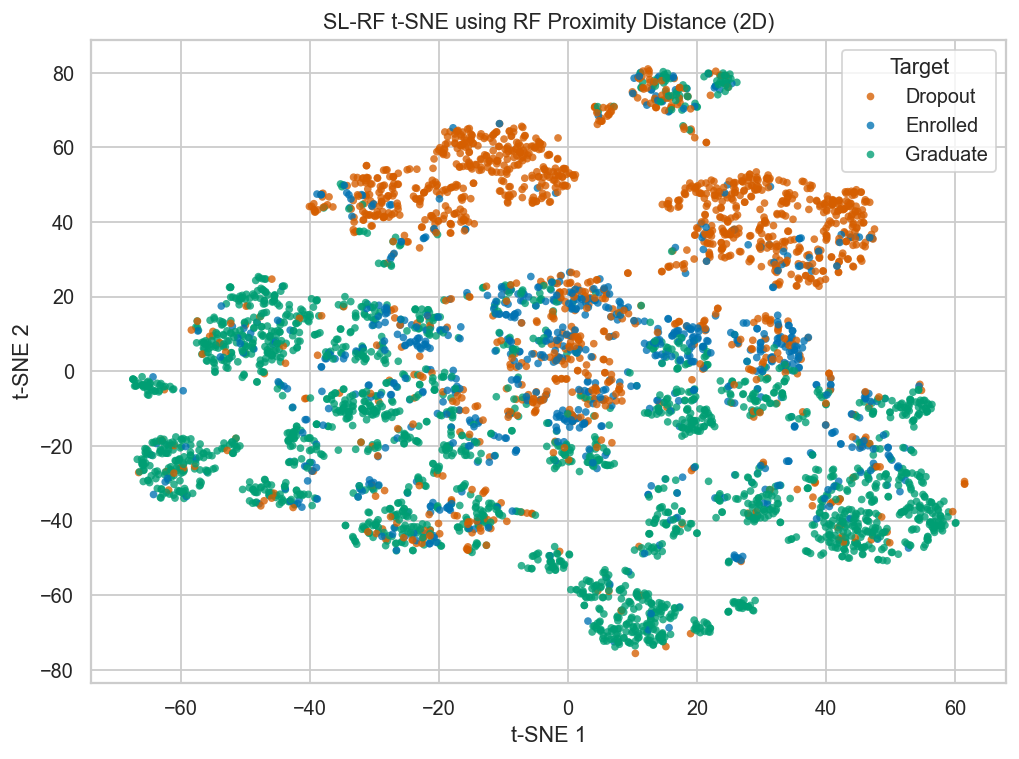

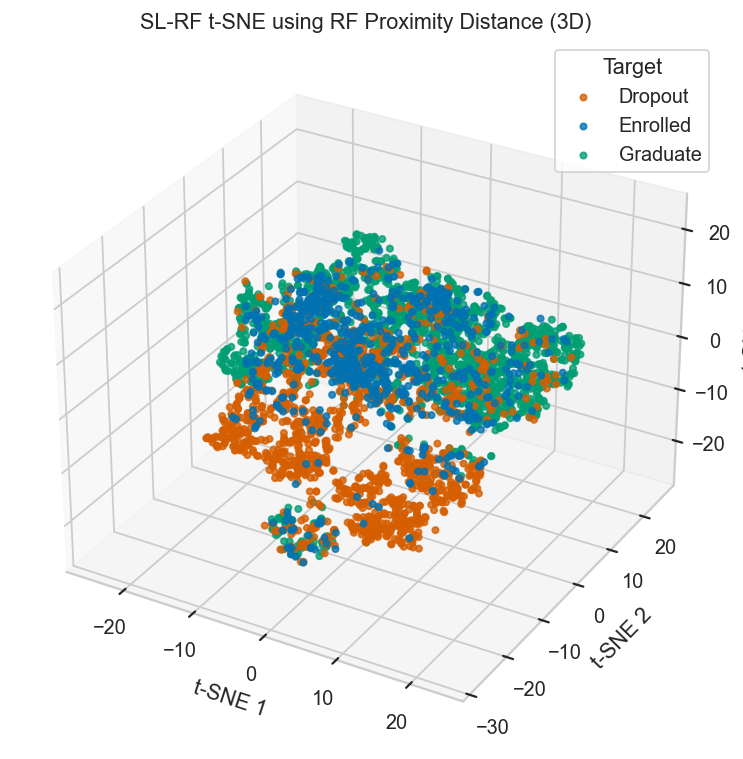

Interactive HTML: e:\Python\Machine-Learning-Project\visualization\outputs\sl_rf_proximity_tsne_3d.html


In [147]:
rf = RandomForestClassifier(
    n_estimators=400,
    max_depth=8,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rf_cv_f1 = cross_val_score(rf, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
rf.fit(X_train, y_train)

rf_metric = evaluate_classifier("SL-RF", rf, X_test, y_test)
rf_metric["CV macro-F1 mean"] = rf_cv_f1.mean()
rf_metric["CV macro-F1 std"] = rf_cv_f1.std()

rf_leaves = rf.apply(X_all)
rf_distance = pairwise_distances(rf_leaves, metric="hamming").astype("float32")
np.fill_diagonal(rf_distance, 0.0)

rf_embedding = run_tsne(rf_distance, n_components=2)
plot_embedding(rf_embedding, "SL-RF t-SNE using RF Proximity Distance (2D)", "sl_rf_proximity_tsne.png")

rf_embedding_3d = run_tsne(rf_distance, n_components=3)
plot_embedding(rf_embedding_3d, "SL-RF t-SNE using RF Proximity Distance (3D)", "sl_rf_proximity_tsne_3d.png")

export_3d_embedding_html(
    rf_embedding_3d,
    "SL-RF t-SNE using RF Proximity Distance (Interactive 3D)",
    "sl_rf_proximity_tsne_3d.html",
)



##  SL-CatBoost Weighted Leaf t-SNE

In [148]:
catboost = CatBoostClassifier(
    loss_function="MultiClass",
    eval_metric="TotalF1:average=Macro",
    auto_class_weights="Balanced",
    depth=6,
    iterations=500,
    l2_leaf_reg=9,
    learning_rate=0.05,
    random_strength=1.0,
    random_seed=42,
    verbose=0,
)

catboost.fit(X_train, y_train, eval_set=(X_val, y_val), verbose=0)
cb_metric = evaluate_classifier("SL-CatBoost", catboost, X_test, y_test)

cb_leaves = catboost.calc_leaf_indexes(X_all)
print("CatBoost leaf matrix:", cb_leaves.shape)

SL-CatBoost
              precision    recall  f1-score   support

     Dropout       0.87      0.75      0.81       214
    Enrolled       0.50      0.71      0.59       119
    Graduate       0.89      0.83      0.86       331

    accuracy                           0.78       664
   macro avg       0.75      0.76      0.75       664
weighted avg       0.81      0.78      0.79       664

CatBoost leaf matrix: (4424, 456)


###  Weighted leaf/path distance

CatBoost weighted distance: (4424, 4424) float32
Distance range: 0.0 0.647870659828186


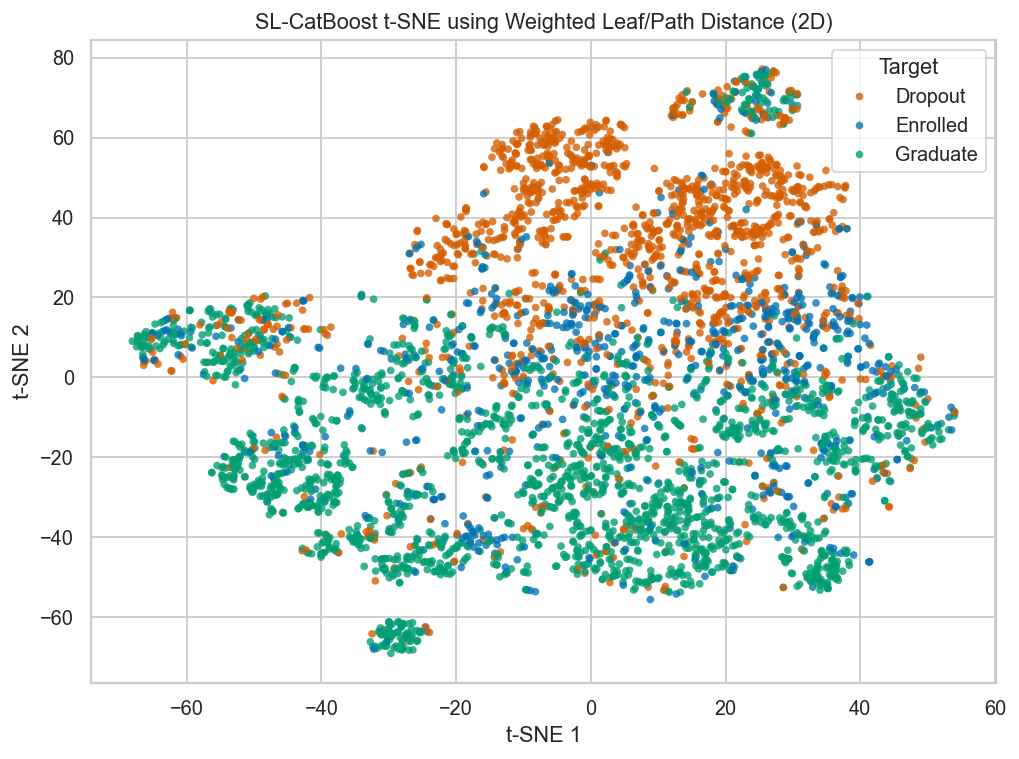

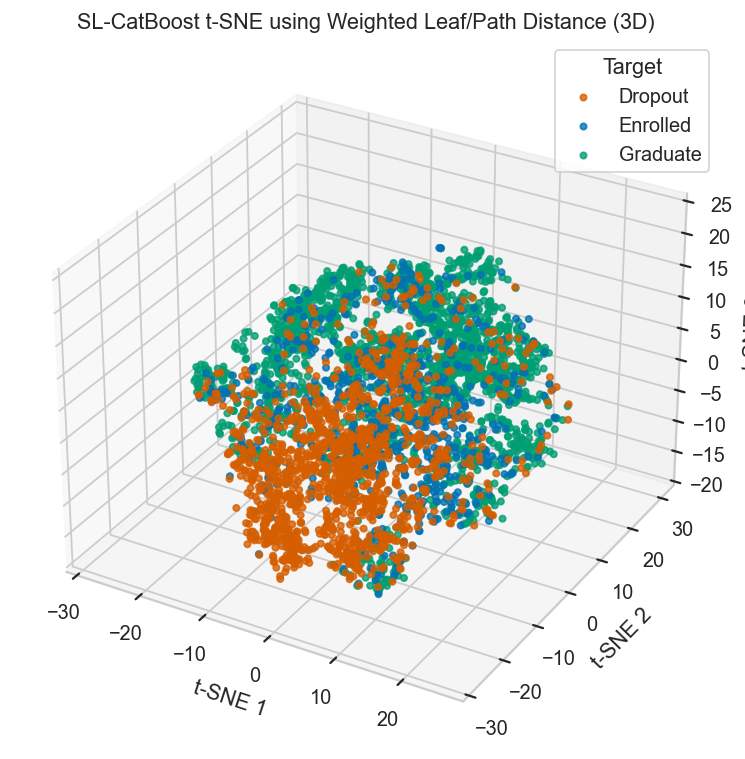

Interactive HTML: e:\Python\Machine-Learning-Project\visualization\outputs\sl_catboost_weighted_leaf_tsne_3d.html


In [149]:
def catboost_weighted_leaf_distance(leaves, depth=6, gamma=0.003, eps=1e-6):
    leaves = leaves.astype(np.uint32)
    n_samples, n_trees = leaves.shape
    path_similarity_sum = np.zeros((n_samples, n_samples), dtype=np.float32)
    weight_sum = np.zeros((n_samples, n_samples), dtype=np.float32)
    tree_weights = np.exp(-gamma * np.arange(n_trees, dtype=np.float32))
    popcount_lookup = np.array([int(value).bit_count() for value in range(2**depth)], dtype=np.float32)

    for t in range(n_trees):
        leaf_t = leaves[:, t]
        xor = np.bitwise_xor(leaf_t[:, None], leaf_t[None, :])
        hamming = popcount_lookup[xor]
        path_similarity = 1.0 - hamming / depth

        _, inverse, counts = np.unique(leaf_t, return_inverse=True, return_counts=True)
        idf = np.log(n_samples / (counts[inverse].astype(np.float32) + eps))
        pair_weight = (idf[:, None] + idf[None, :]) * 0.5
        weighted = tree_weights[t] * pair_weight

        path_similarity_sum += weighted * path_similarity
        weight_sum += weighted

    similarity = path_similarity_sum / np.maximum(weight_sum, eps)
    similarity = np.clip(similarity, 0.0, 1.0)
    distance = (1.0 - similarity).astype("float32")
    np.fill_diagonal(distance, 0.0)
    return distance

cb_distance = catboost_weighted_leaf_distance(cb_leaves, depth=6, gamma=0.003)
print("CatBoost weighted distance:", cb_distance.shape, cb_distance.dtype)
print("Distance range:", float(cb_distance.min()), float(cb_distance.max()))

cb_embedding = run_tsne(cb_distance, n_components=2)
plot_embedding(
    cb_embedding,
    "SL-CatBoost t-SNE using Weighted Leaf/Path Distance (2D)",
    "sl_catboost_weighted_leaf_tsne.png",
)

cb_embedding_3d = run_tsne(cb_distance, n_components=3)
plot_embedding(
    cb_embedding_3d,
    "SL-CatBoost t-SNE using Weighted Leaf/Path Distance (3D)",
    "sl_catboost_weighted_leaf_tsne_3d.png",
)

export_3d_embedding_html(
    cb_embedding_3d,
    "SL-CatBoost t-SNE using Weighted Leaf/Path Distance (Interactive 3D)",
    "sl_catboost_weighted_leaf_tsne_3d.html",
)



## 5. SL-CatBoost Leaf Co-occurrence Proximity Matrix

This section uses the standard CatBoost proximity matrix: two samples are more similar when they land in the same leaf across more CatBoost trees. The distance is `1 - proximity`, and clustering is run directly on this precomputed distance matrix.


CatBoost proximity distance: (4424, 4424) float32
Distance range: 0.0 0.984649121761322
CatBoost proximity clustering summary:


,cluster,size,dominant,dominant_ratio,zone,Dropout,Enrolled,Graduate
0,0,28,Dropout,0.7500,atypical_danger,21,3,4
1,1,21,Dropout,0.9048,atypical_danger,19,2,0
2,2,1390,Dropout,0.7216,atypical_danger,1003,261,126
3,3,9,Dropout,0.7778,atypical_danger,7,1,1
4,7,14,Dropout,0.7143,atypical_danger,10,1,3
5,4,275,Graduate,0.6436,swing_ambiguous,63,35,177
6,5,2684,Graduate,0.7068,swing_ambiguous,298,489,1897
7,6,3,Enrolled,0.6667,swing_ambiguous,0,2,1


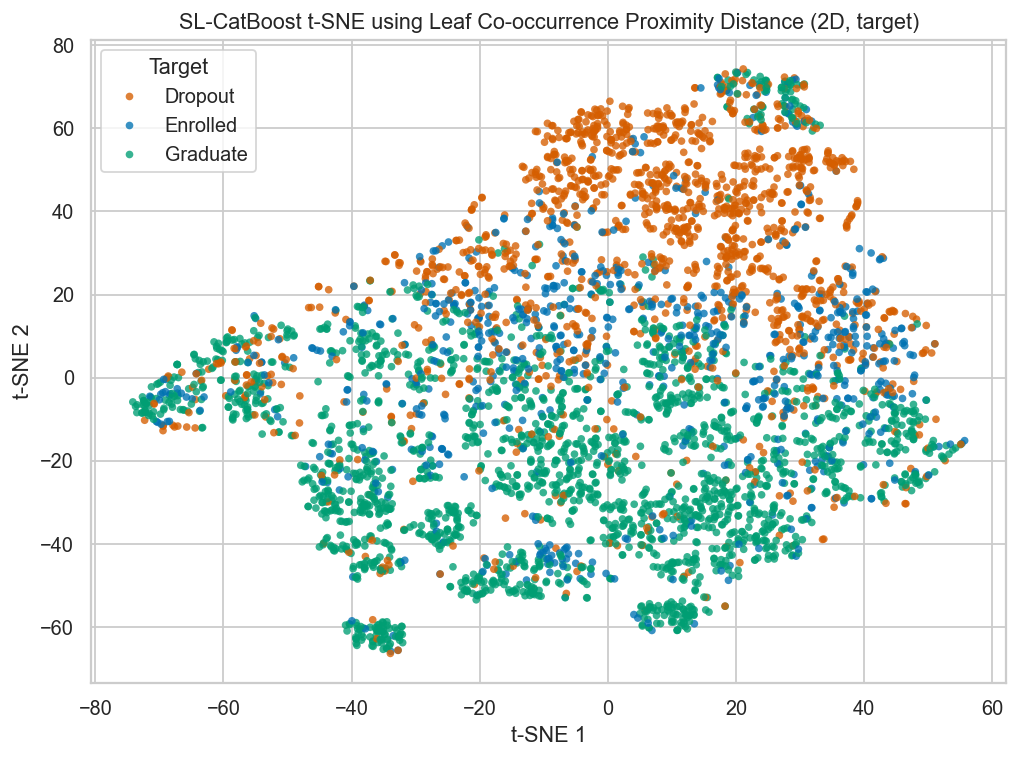

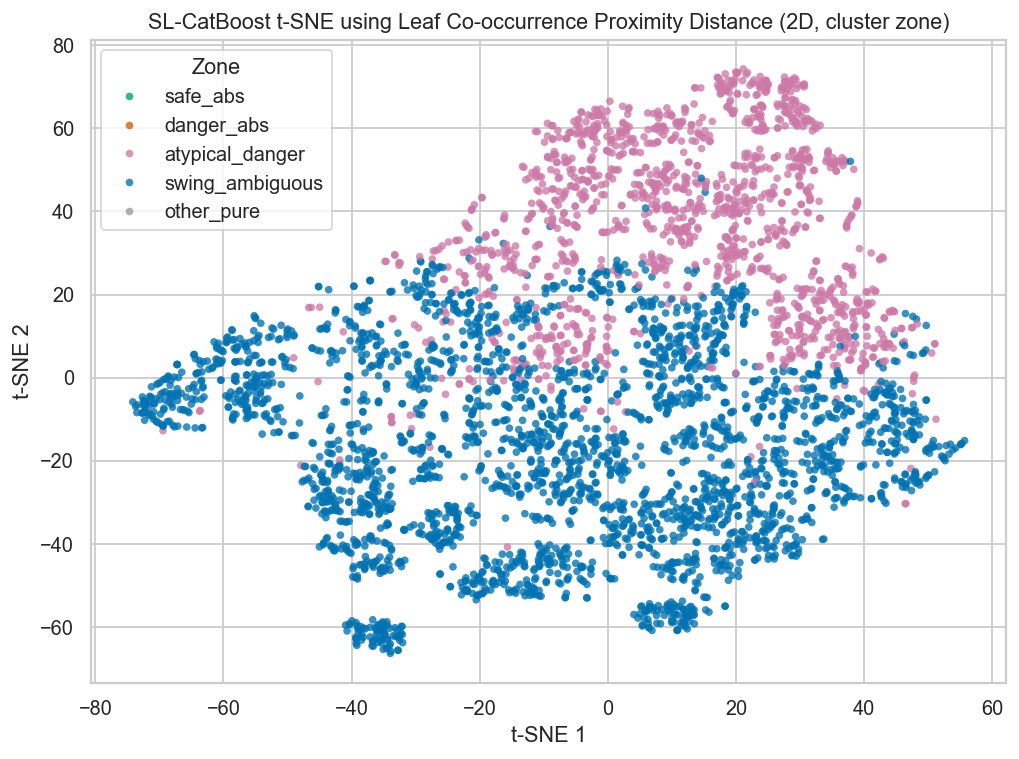

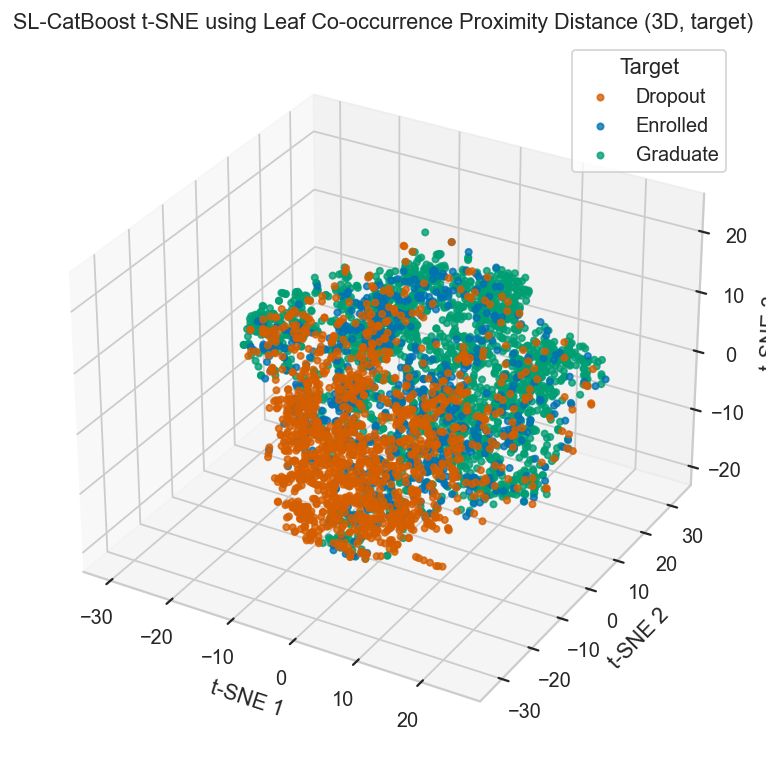

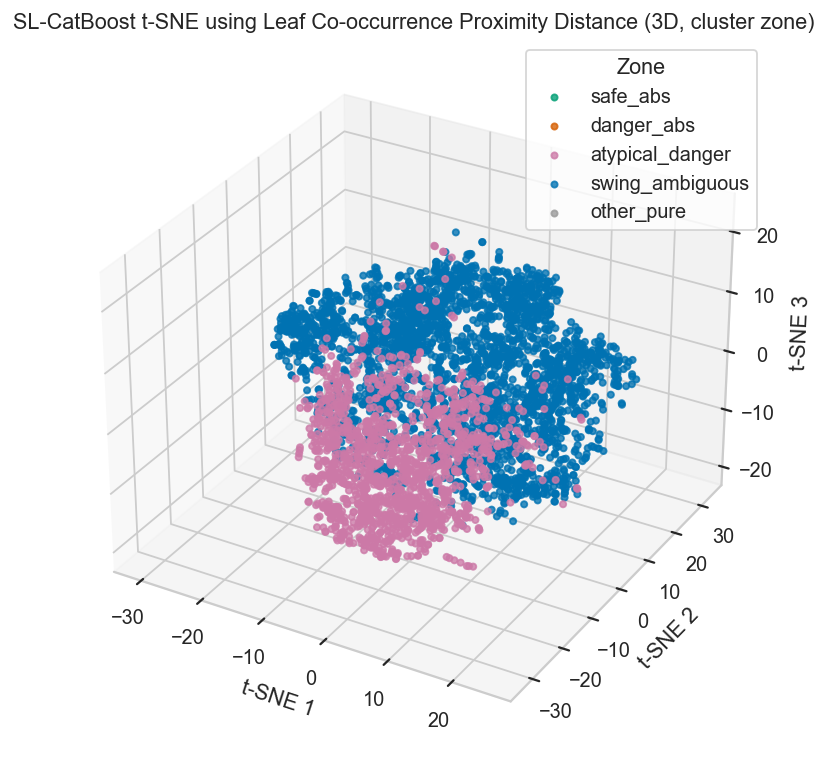

Interactive HTML: e:\Python\Machine-Learning-Project\visualization\outputs\sl_catboost_leaf_proximity_tsne_3d.html
Interactive HTML: e:\Python\Machine-Learning-Project\visualization\outputs\sl_catboost_leaf_proximity_cluster_zone_tsne_3d.html


In [150]:
def catboost_leaf_cooccurrence_distance(leaves):
    leaves = leaves.astype(np.int32)
    n_samples, n_trees = leaves.shape
    proximity = np.zeros((n_samples, n_samples), dtype=np.float32)

    for t in range(n_trees):
        leaf_t = leaves[:, t]
        proximity += leaf_t[:, None] == leaf_t[None, :]

    proximity /= np.float32(n_trees)
    distance = (1.0 - proximity).astype("float32")
    np.fill_diagonal(distance, 0.0)
    return distance

cb_proximity_distance = catboost_leaf_cooccurrence_distance(cb_leaves)
print("CatBoost proximity distance:", cb_proximity_distance.shape, cb_proximity_distance.dtype)
print("Distance range:", float(cb_proximity_distance.min()), float(cb_proximity_distance.max()))

cb_proximity_cluster_labels = run_cluster_on_distance(
    cb_proximity_distance,
    method="agglomerative",
    n_clusters=8,
)
cb_proximity_cluster_summary = zone_summary_from_clusters(cb_proximity_cluster_labels)
print("CatBoost proximity clustering summary:")
display(cb_proximity_cluster_summary)

cb_proximity_cluster_zone_map = cb_proximity_cluster_summary.set_index("cluster")["zone"]
cb_proximity_cluster_zones = pd.Series(cb_proximity_cluster_labels).map(cb_proximity_cluster_zone_map).to_numpy()

cb_proximity_embedding = run_tsne(cb_proximity_distance, n_components=2)
plot_embedding(
    cb_proximity_embedding,
    "SL-CatBoost t-SNE using Leaf Co-occurrence Proximity Distance (2D, target)",
    "sl_catboost_leaf_proximity_tsne.png",
)
plot_embedding(
    cb_proximity_embedding,
    "SL-CatBoost t-SNE using Leaf Co-occurrence Proximity Distance (2D, cluster zone)",
    "sl_catboost_leaf_proximity_cluster_zone_tsne.png",
    color_values=cb_proximity_cluster_zones,
    color_name="Zone",
    color_order=list(zone_palette.keys()),
    color_palette=zone_palette,
)

cb_proximity_embedding_3d = run_tsne(cb_proximity_distance, n_components=3)
plot_embedding(
    cb_proximity_embedding_3d,
    "SL-CatBoost t-SNE using Leaf Co-occurrence Proximity Distance (3D, target)",
    "sl_catboost_leaf_proximity_tsne_3d.png",
)
plot_embedding(
    cb_proximity_embedding_3d,
    "SL-CatBoost t-SNE using Leaf Co-occurrence Proximity Distance (3D, cluster zone)",
    "sl_catboost_leaf_proximity_cluster_zone_tsne_3d.png",
    color_values=cb_proximity_cluster_zones,
    color_name="Zone",
    color_order=list(zone_palette.keys()),
    color_palette=zone_palette,
)

export_3d_embedding_html(
    cb_proximity_embedding_3d,
    "SL-CatBoost t-SNE using Leaf Co-occurrence Proximity Distance (Interactive 3D, target)",
    "sl_catboost_leaf_proximity_tsne_3d.html",
)
export_3d_embedding_html(
    cb_proximity_embedding_3d,
    "SL-CatBoost t-SNE using Leaf Co-occurrence Proximity Distance (Interactive 3D, cluster zone)",
    "sl_catboost_leaf_proximity_cluster_zone_tsne_3d.html",
    color_values=cb_proximity_cluster_zones,
    color_name="Zone",
    color_order=list(zone_palette.keys()),
    color_palette=zone_palette,
    cluster_labels=cb_proximity_cluster_labels,
    zones=cb_proximity_cluster_zones,
)

##  Compact Comparison

In [151]:
classifier_metrics = pd.DataFrame([rf_metric, cb_metric])
display(classifier_metrics.round(4))

quality = pd.DataFrame(
    [
        distance_quality("SL-RF proximity", rf_distance, rf_embedding),
        distance_quality("SL-CatBoost weighted leaf", cb_distance, cb_embedding),
        distance_quality("SL-CatBoost leaf co-occurrence proximity", cb_proximity_distance, cb_proximity_embedding),
    ]
)
quality["Random same-label baseline"] = pd.Series(y_all).value_counts(normalize=True).pow(2).sum()
display(quality.round(4))


,Model,Test accuracy,Test macro-F1,Test AUC OVR,CV macro-F1 mean,CV macro-F1 std
0,SL-RF,0.7786,0.7373,0.9030,0.6981,0.0167
1,SL-CatBoost,0.7846,0.7505,0.9109,NaN,NaN


,Method,Distance silhouette,Embedding silhouette,Distance KNN label agreement@15,Random same-label baseline
0,SL-RF proximity,0.0288,0.0279,0.6933,0.3847
1,SL-CatBoost weighted leaf,0.0641,0.0755,0.6849,0.3847
2,SL-CatBoost leaf co-occurrence proximity,0.0348,0.0737,0.6704,0.3847


## 7. Brief Conclusion

The original SL-RF and SL-CatBoost weighted leaf/path t-SNE analyses are kept, with 3D t-SNE views added after the original 2D graphs.
The added CatBoost leaf co-occurrence proximity branch uses same-leaf frequency across trees as the distance basis, clusters directly on that distance matrix, then visualizes the same distance matrix with 2D and 3D t-SNE.


# Supervised UMAP Report

Short companion report to the RF proximity t-SNE notebook.
It uses `data/processed_fullyonehot/fullyonehot.csv`, fits supervised UMAP on the training split only, then transforms validation/test samples into the same 2D space.

In [152]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    import umap
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "This notebook requires umap-learn. Install with: "
        "python -m pip install umap-learn"
    ) from exc

from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import LabelEncoder, StandardScaler

RANDOM_STATE = 42
PROJECT = Path.cwd()
if not (PROJECT / "data").exists():
    PROJECT = PROJECT.parent

OUT_DIR = PROJECT / "visualization" / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 130
sns.set_theme(style="whitegrid", context="notebook")

In [153]:
DATA_PATH = PROJECT / "data" / "processed_fullyonehot" / "fullyonehot.csv"
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()

target_col = "Target"
feature_cols = [c for c in df.columns if c != target_col]

label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(df[target_col])

train_idx, holdout_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y_all,
    shuffle=True,
)
val_idx, test_idx = train_test_split(
    holdout_idx,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_all[holdout_idx],
    shuffle=True,
)

X_all_raw = df[feature_cols].astype("float32")
scaler = StandardScaler()
X_train = scaler.fit_transform(X_all_raw.iloc[train_idx])
X_val = scaler.transform(X_all_raw.iloc[val_idx])
X_test = scaler.transform(X_all_raw.iloc[test_idx])
X_all = scaler.transform(X_all_raw)

y_train = y_all[train_idx]
y_val = y_all[val_idx]
y_test = y_all[test_idx]

split_all = np.empty(len(df), dtype=object)
split_all[train_idx] = "train"
split_all[val_idx] = "val"
split_all[test_idx] = "test"

print("Data path:", DATA_PATH)
print("Full one-hot data:", df.shape)
print("Train / Val / Test:", X_train.shape, X_val.shape, X_test.shape)
display(pd.Series(label_encoder.inverse_transform(y_all)).value_counts().to_frame("count"))

Data path: e:\Python\Machine-Learning-Project\data\processed_fullyonehot\fullyonehot.csv
Full one-hot data: (4424, 262)
Train / Val / Test: (3096, 261) (664, 261) (664, 261)


,count
2,2209
0,1421
1,794


## 2. Fit Supervised UMAP

In [154]:
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=30,
    min_dist=0.05,
    metric="euclidean",
    target_metric="categorical",
    target_weight=0.7,
    random_state=RANDOM_STATE,
    low_memory=True,
)

train_embedding = reducer.fit_transform(X_train, y=y_train)
val_embedding = reducer.transform(X_val)
test_embedding = reducer.transform(X_test)

embedding = np.empty((len(df), 2), dtype="float32")
embedding[train_idx] = train_embedding
embedding[val_idx] = val_embedding
embedding[test_idx] = test_embedding

print("Embedding:", embedding.shape)
print("Fitted on train labels only; val/test are transformed.")

c:\Users\30566\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



Embedding: (4424, 2)
Fitted on train labels only; val/test are transformed.


## 3. Plot Supervised UMAP

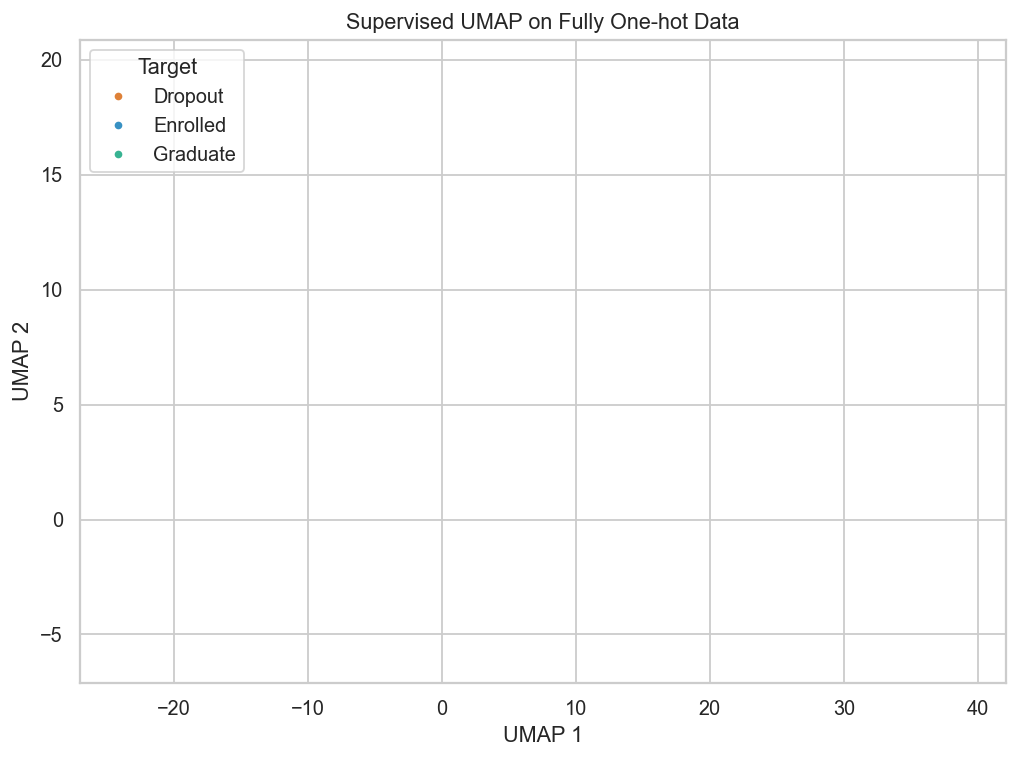

In [155]:
plot_df = pd.DataFrame(embedding, columns=["UMAP1", "UMAP2"])
plot_df["Target"] = label_encoder.inverse_transform(y_all)
plot_df["Split"] = split_all

palette = {"Dropout": "#d55e00", "Enrolled": "#0072b2", "Graduate": "#009e73"}
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    data=plot_df,
    x="UMAP1",
    y="UMAP2",
    hue="Target",
    hue_order=["Dropout", "Enrolled", "Graduate"],
    palette=palette,
    s=18,
    alpha=0.78,
    linewidth=0,
    ax=ax,
)
ax.set_title("Supervised UMAP on Fully One-hot Data")
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.legend(title="Target", frameon=True)
plt.tight_layout()
fig.savefig(OUT_DIR / "supervised_umap.png", bbox_inches="tight")
plt.show()

## 4. Compact Quality Checks

In [156]:
def knn_label_agreement(points, labels, k=15):
    nn = NearestNeighbors(n_neighbors=k + 1)
    nn.fit(points)
    indices = nn.kneighbors(return_distance=False)[:, 1:]
    return (labels[indices] == labels[:, None]).mean()

quality = {
    "Embedding silhouette": silhouette_score(embedding, y_all),
    "Embedding KNN label agreement@15": knn_label_agreement(embedding, y_all, k=15),
    "Random same-label baseline": pd.Series(y_all).value_counts(normalize=True).pow(2).sum(),
}
display(pd.Series(quality).to_frame("value").round(4))

,value
Embedding silhouette,0.5639
Embedding KNN label agreement@15,0.8672
Random same-label baseline,0.3847


## 5. Brief Conclusion

Supervised UMAP creates a label-aware 2D map. This notebook fits the UMAP manifold using training labels only, then projects validation and test samples.
Therefore it is stricter than fitting supervised UMAP on the full labeled dataset, but it is still a supervised visualization rather than unsupervised clustering.